# Phần B — Vai trò của biến thêm vào

Ở phần A ([variable_type.ipynb](variable_type.ipynb)), số biến giữ nguyên và chỉ kiểu dữ liệu của X2 thay đổi. Phần B giữ X1, X2 liên tục như **T0**, thêm một biến X3 ~ N(0, 1) và chỉ đổi **vai trò** của X3. Mỗi kịch bản phân tích bằng hai tập biến, trên cùng dữ liệu của từng rep:

- **S2** = {X1, X2}: không đưa X3 vào.
- **S3** = {X1, X2, X3}: đưa X3 vào cả mô hình PS lẫn mô hình outcome.

Câu hỏi: nên đưa X3 vào khi nào? Câu trả lời phụ thuộc X3 tác động lên A, lên Y, hay lên cả hai.

| Mã | Vai trò của X3 | γ3 | β3 | Câu hỏi | Kỳ vọng (pilot, OLS, n = 2000) |
|---|---|---|---|---|---|
| **V0** | không có X3 | không có | không có | mốc so sánh, trùng **T0** | bias 0; SD 0.048 |
| **V1** | confounder | 0.5 | 0.5 | bỏ sót (S2) chệch bao nhiêu? | S2 bias **+0.237**, coverage ≈ 0; S3 không chệch |
| **V2** | chỉ tác động lên Y | 0 | 0.5 | đưa vào có giảm phương sai? | bias 0; SD 0.053 → **0.046** |
| **V3** | chỉ tác động lên A | 1.0 | 0 | đưa vào có hại? | bias 0; SD 0.047 → **0.054**; ESS/n 0.88 → 0.64 |
| **V4** | không tác động gì | 0 | 0 | chi phí của một biến thừa | bias 0; SD gần như không đổi |
| **V5** | confounder tương quan với X1 (ρ = 0.7) | 0.5 | 0.5 | bỏ sót khi X3 tương quan với biến đã có | S2 bias **+0.124**, khoảng một nửa **V1**; S3 không chệch |

**Cách đọc.** Mục 0 gồm những thứ dùng chung, không đổi giữa các kịch bản: estimator, vòng Monte Carlo, hình. Sau đó mỗi kịch bản là một phần tự chứa gồm 6 cell:
(a) công thức DGP; (b) hàm sinh dữ liệu, mỗi dòng khác **V0** có chú thích `# KHÁC V0`; (c) bảng so sánh với mốc kèm kiểm tra;
(d) một mẫu rất lớn để thấy giới hạn của từng estimator; (e) Monte Carlo; (f) nhận xét. **V0** là mốc nên hàm sinh dữ liệu nằm ở mục 0.2. Một số kịch bản có thêm hình cơ chế.

Mọi PS trong estimator, balance và ESS đều là logistic **ước lượng**, không dùng PS thật, không clip. Các CI là Wald 95%. **V7** (biến hậu điều trị) và phần C là tùy chọn, chưa triển khai.

Mặc định R = 1000 lần lặp; đặt `RA_VARIABLE_REPS=200` để chạy thử, `RA_VARIABLE_RUN_MC=0` để chỉ đọc lại CSV trong `results/`.

## 0. Phần dùng chung
### 0.1 Thư viện, hằng số, kiểu hình

In [1]:
import os
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import scipy
from scipy.special import expit
from scipy.stats import norm
import statsmodels
import statsmodels.api as sm
from statsmodels.tools.sm_exceptions import PerfectSeparationWarning
from IPython import get_ipython
if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter, LogLocator, NullLocator
from IPython.display import display, Markdown

TAU = 2.0                 # ATE thật ở mọi kịch bản
SIGMA = 1.0
N_REF = 200_000           # mẫu tham chiếu để hiệu chỉnh gamma0 và kiểm tra DGP
N_LARGE = 2_000_000       # một mẫu rất lớn: xấp xỉ giới hạn của từng estimator
N_VALUES = tuple(sorted(int(v) for v in
                        os.environ.get("RA_VARIABLE_N", "250,500,1000,2000,4000,8000").split(",")))
R = int(os.environ.get("RA_VARIABLE_REPS", "1000"))
RUN_MC = os.environ.get("RA_VARIABLE_RUN_MC", "1") != "0"
SEED = 20261021           # trùng phần A, để V0 ở đây tái lập đúng T0 của phần A
METHODS = ("Naive", "OLS", "IPTW", "AIPW")
ADJUSTED = ("OLS", "IPTW", "AIPW")
Z95 = norm.ppf(0.975)

RESULT_DIR = next((p for p in (Path.cwd(), Path.cwd() / "scenario/variable_scenario",
                              Path.cwd() / "ra_causal/scenario/variable_scenario")
                   if (p / "add_variable.ipynb").exists()), None)
if RESULT_DIR is None:
    raise FileNotFoundError("Hãy chạy kernel từ variable_scenario, ra_causal hoặc Seminar.")
RESULT_DIR = RESULT_DIR / "results"
FIG_DIR = RESULT_DIR / "figures_B"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Màu phương pháp giữ như phần A và phần D.
INK, INK_2, INK_3 = "#0b0b0b", "#52514e", "#8a8986"
GRID, SHADE = "#e9e8e4", "#f0efec"
METHOD_STYLE = {
    "Naive": dict(color="#7a7974", marker="x"),
    "OLS":   dict(color="#2a78d6", marker="o"),
    "IPTW":  dict(color="#eb6834", marker="s"),
    "AIPW":  dict(color="#1baf7a", marker="^"),
}
CATEGORICAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 9,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK_2, "text.color": INK,
    "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.titlesize": 10, "axes.titleweight": "bold",
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": .6,
    "legend.frameon": False, "lines.linewidth": 1.8, "lines.markersize": 5.5,
})
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
print(f"R={R}; n={N_VALUES}; chạy MC={RUN_MC}; results={RESULT_DIR}")

R=1000; n=(250, 500, 1000, 2000, 4000, 8000); chạy MC=True; results=/home/doan/Seminar/ra_causal/scenario/variable_scenario/results


### 0.2 Mốc V0, hai tập biến và bước sinh A, Y dùng chung

**V0** (trùng **T0** của phần A):

$$
\operatorname{logit} e(X) = \gamma_0 + 0.5X_1 + 0.5X_2,\qquad
\mu_0(X) = 0.5X_1 + 0.5X_2,\qquad
\tau(X) = 2,\qquad X_1, X_2 \sim N(0,1)
$$

Mọi kịch bản dùng chung bước cuối:

$$
A \sim \text{Bernoulli}\big(e(X)\big),\qquad Y = \mu_0(X) + \tau(X)\,A + \varepsilon,\quad \varepsilon \sim N(0, 1)
$$

Mỗi kịch bản chỉ viết lại hàm `dgp_<mã>(n, rng)`. Hàm này trả về X, phần tuyến tính của logit PS (chưa có γ0), μ0(X) và τ(X).
γ0 được hiệu chỉnh trên mẫu tham chiếu N_REF để P(A=1) = 0.5. `simulate` không đổi giữa các kịch bản.

`ANALYSES` khai báo hai tập biến. `make_design` thêm cột chặn; cùng một design được dùng cho OLS, PS và outcome của AIPW.

In [2]:
def calibrate_gamma0(lin, target=0.5):
    # Chia đôi: chọn gamma0 sao cho mean(expit(gamma0 + lin)) = target.
    lo, hi = -50., 50.
    for _ in range(60):
        mid = (lo + hi) / 2
        if expit(mid + lin).mean() < target:
            lo = mid
        else:
            hi = mid
    return (lo + hi) / 2


def reference_sample(dgp):
    # Mẫu tham chiếu cố định (seed 12345), độc lập với Monte Carlo.
    return dgp(N_REF, np.random.default_rng(12345))


def gamma0_for(dgp, target=0.5):
    _, lin, _, _ = reference_sample(dgp)
    return calibrate_gamma0(lin, target)


def simulate(dgp, gamma0, n, seed):
    # Bước chung: A ~ Bernoulli(e(X)), Y = mu0 + tau*A + eps. Truth giữ riêng.
    rng = np.random.default_rng(seed)
    X, lin, mu0, tau = dgp(n, rng)
    e = expit(gamma0 + lin)
    a = rng.binomial(1, e)
    eps = rng.normal(0, SIGMA, n)
    df = pd.DataFrame({**X, "A": a, "Y": mu0 + tau * a + eps})
    truth = pd.DataFrame({"e": e, "tau": tau, "Y0": mu0 + eps, "Y1": mu0 + tau + eps})
    return df, truth


def dgp_V0(n, rng):
    x1 = rng.normal(size=n)
    x2 = rng.normal(size=n)
    lin = 0.5*x1 + 0.5*x2             # logit e(X) - gamma0
    mu0 = 0.5*x1 + 0.5*x2             # mu0(X)
    tau = np.full(n, TAU)             # tau(X) = 2
    return {"X1": x1, "X2": x2}, lin, mu0, tau


GAMMA0_V0 = gamma0_for(dgp_V0, target=0.5)


def simulate_V0(n, seed):
    return simulate(dgp_V0, GAMMA0_V0, n, seed)


ANALYSES_V0 = {"S2": ("X1", "X2")}
ANALYSES = {"S2": ("X1", "X2"), "S3": ("X1", "X2", "X3")}


def make_design(df, cols):
    # Design người phân tích dùng: chặn + các biến trong tập cols.
    return np.column_stack([np.ones(len(df))] + [df[c].to_numpy(float) for c in cols])


FORMULA_V0 = {"X3": "không có", "logit e(X)": "γ0 + 0.5·X1 + 0.5·X2",
              "μ0(X)": "0.5·X1 + 0.5·X2", "τ(X)": "2", "P(A=1) mục tiêu": "0.5"}
print(f"V0: gamma0 = {GAMMA0_V0:.4f}")

V0: gamma0 = -0.0012


### 0.3 Bốn estimator

| Phương pháp | Ước lượng | SE |
|---|---|---|
| Naive | $\bar Y_1 - \bar Y_0$ | Welch |
| OLS | hệ số của A trong $Y \sim 1 + X + A$ | HC1 |
| IPTW (Hájek) | $\dfrac{\sum A_iY_i/\hat e_i}{\sum A_i/\hat e_i} - \dfrac{\sum (1-A_i)Y_i/(1-\hat e_i)}{\sum (1-A_i)/(1-\hat e_i)}$ | IF có hiệu chỉnh việc ước lượng $\hat e$ |
| AIPW | $\frac1n\sum_i \Big[\hat m_1 - \hat m_0 + \frac{A_i(Y_i-\hat m_1)}{\hat e_i} - \frac{(1-A_i)(Y_i-\hat m_0)}{1-\hat e_i}\Big]$ | $\mathrm{SD}(\psi_i)/\sqrt n$ |

$\hat m_t$ là OLS fit riêng trên nhóm $A = t$ với cùng design. Logistic không penalize, không clip. Fit không xác định hoặc không hội tụ được ghi `status` và NaN, vẫn giữ đủ số lần lặp.

Bốn estimator copy nguyên từ phần A. Phần B không thêm RA của phần D, vì ở đây τ hằng số nên OLS không có lỗi "một hệ số chung cho A" để RA sửa.

In [3]:
class FitFailure(ValueError):
    pass


def _check_rank(design):
    if np.linalg.matrix_rank(design) < design.shape[1]:
        raise FitFailure("rank_deficient")


def fit_propensity(A, design):
    x = np.asarray(design, float)
    _check_rank(x)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        fit = sm.Logit(A, x).fit(disp=False, maxiter=100)
    if any(issubclass(w.category, PerfectSeparationWarning) for w in caught):
        raise FitFailure("perfect_separation")
    if not fit.mle_retvals.get("converged", False):
        raise FitFailure("ps_not_converged")
    e = np.asarray(fit.predict(x))
    if not np.isfinite(e).all() or np.any((e <= 0) | (e >= 1)):
        raise FitFailure("ps_at_boundary")
    return e  # không clip, không regularize


def est_naive(Y, A, design):
    y1, y0 = Y[A == 1], Y[A == 0]
    if min(len(y1), len(y0)) < 2:
        raise FitFailure("treatment_group_too_small")
    return y1.mean() - y0.mean(), np.sqrt(y1.var(ddof=1)/len(y1) + y0.var(ddof=1)/len(y0))


def est_ols(Y, A, design):
    x = np.column_stack([np.asarray(design), A])
    _check_rank(x)
    fit = sm.OLS(Y, x).fit(cov_type="HC1")
    return fit.params[-1], fit.bse[-1]


def est_iptw(Y, A, design, e_hat=None):
    x = np.asarray(design, float)
    e = fit_propensity(A, x) if e_hat is None else e_hat
    w1, w0 = A/e, (1-A)/(1-e)
    mu1, mu0 = (w1 @ Y)/w1.sum(), (w0 @ Y)/w0.sum()
    psi = w1*(Y-mu1)/w1.mean() - w0*(Y-mu0)/w0.mean()
    a1 = x.T @ (-w1*(Y-mu1)*(1-e)) / len(Y) / w1.mean()
    a0 = x.T @ (w0*(Y-mu0)*e) / len(Y) / w0.mean()
    information = (x * (e*(1-e))[:, None]).T @ x / len(Y)
    score = x * (A-e)[:, None]
    influence = psi + score @ np.linalg.solve(information, a1-a0)
    return mu1-mu0, influence.std(ddof=1)/np.sqrt(len(Y))


def est_aipw(Y, A, design, e_hat=None):
    x = np.asarray(design, float)
    e = fit_propensity(A, x) if e_hat is None else e_hat
    predictions = {}
    for t in (0, 1):
        xt = x[A == t]
        _check_rank(xt)
        if len(xt) <= x.shape[1]:
            raise FitFailure("outcome_group_too_small")
        b = np.linalg.lstsq(xt, Y[A == t], rcond=None)[0]
        predictions[t] = x @ b
    m1, m0 = predictions[1], predictions[0]
    psi = m1-m0 + A*(Y-m1)/e - (1-A)*(Y-m0)/(1-e)
    return psi.mean(), psi.std(ddof=1)/np.sqrt(len(Y))


def estimate_all(df, design):
    Y, A = df.Y.to_numpy(), df.A.to_numpy()
    x = np.asarray(design, float)
    estimates, status = {}, {}
    failure_types = (FitFailure, np.linalg.LinAlgError, ValueError,
                     sm.tools.sm_exceptions.PerfectSeparationError)

    def record(method, call):
        try:
            value = tuple(float(v) for v in call())
            if not np.isfinite(value).all() or value[1] < 0:
                raise FitFailure("nonfinite_estimate_or_se")
            estimates[method], status[method] = value, "ok"
        except failure_types as exc:
            estimates[method], status[method] = (np.nan, np.nan), str(exc)

    record("Naive", lambda: est_naive(Y, A, x))
    record("OLS", lambda: est_ols(Y, A, x))
    try:
        e, ps_status = fit_propensity(A, x), "ok"
    except failure_types as exc:
        e, ps_status = None, str(exc)
    for method, fn in (("IPTW", est_iptw), ("AIPW", est_aipw)):
        if e is None:
            estimates[method], status[method] = (np.nan, np.nan), ps_status
        else:
            record(method, lambda fn=fn: fn(Y, A, x, e))
    return estimates, e, status, ps_status

### 0.4 Công cụ: so sánh DGP, mẫu lớn, cơ chế OLS, Monte Carlo, tóm tắt

- `smd_table`, `diagnostics`: SMD dùng mẫu số trước weighting. Chẩn đoán lưu ESS, PS, trọng số, balance. `x3_smd_after` là SMD của X3 sau weighting, kể cả khi X3 không có trong mô hình: chỉ mô phỏng mới biết được con số này.
- `show_vs_base`: in bảng công thức kịch bản cạnh mốc, kèm số trên mẫu tham chiếu (γ0, P(A=1), Var[X3], Corr(X1, X3), ESS/n với e thật). Kiểm tra τ = 2, P(A=1) đúng mục tiêu và Var[X3] = 1 (nếu có X3) bằng `assert`.
- `population_limits`: giới hạn lý thuyết của cả bốn estimator với từng tập biến, tính trên mẫu tham chiếu bằng cách thay A bằng e(X) thật và bỏ ε.
- `large_sample_check`: một mẫu n = 2.000.000, phân tích bằng cả S2 và S3. Bias ở đây xấp xỉ **giới hạn** của từng estimator khi n → ∞; đối chiếu với `population_limits` và với số pilot trong README (pilot chỉ có cho OLS và một phần Naive).
- `show_fwl`: công thức của OLS theo định lý Frisch–Waugh–Lovell, tính trên mẫu tham chiếu (xem dưới).
- `run_mc`: `SeedSequence([SEED, mã, n]).spawn(R)` như phần A; các tập biến của cùng rep dùng cùng dữ liệu nên so sánh S2 và S3 là so sánh ghép cặp. Lưu `results/<mã>.csv` và `results/<mã>_diagnostics.csv`.
- `report`: bảng tóm tắt theo n, kiểm tra OLS so với giới hạn mẫu lớn và công thức FWL, hai hình.

**Công thức FWL cho hệ số của A.** Gọi $L(X)$ là phép chiếu tuyến tính của A lên design của tập biến đang xét, $\tilde A = A - L(X)$. Khi τ hằng số:

$$
\text{bias OLS} = \frac{E\big[(e(X) - L(X))\,\mu_0(X)\big]}{\mathrm{Var}(\tilde A)},\qquad
\mathrm{Var}(\tilde A) = E\big[e(X)\,(1 - L(X))\big],\qquad
\mathrm{SD}(\hat\tau_{\text{OLS}}) \approx \frac{\sigma_{\text{res}}}{\sqrt n\,\mathrm{SD}(\tilde A)}
$$

với $\sigma_{\text{res}}$ là độ lệch chuẩn phần dư của hồi quy Y lên design và A. Vì $e - L$ trực giao với design, tử số chỉ còn phần của μ0 mà design không có. Do đó X3 ảnh hưởng tới OLS qua đúng hai kênh: **σ_res** (phần Y được giải thích) và **SD(Ã)** (phần A còn lại để so sánh).

In [4]:
def ess_ratio(w):
    return w.sum()**2/(w @ w)/len(w)


def smd_table(covariates, A, weights=None):
    # Mẫu số tính trước weighting, giống nhau trước và sau khi cân bằng.
    w = np.ones(len(A)) if weights is None else np.asarray(weights)
    rows = []
    for col in covariates:
        x = covariates[col].to_numpy(float)
        m1 = np.average(x[A == 1], weights=w[A == 1])
        m0 = np.average(x[A == 0], weights=w[A == 0])
        denom = np.sqrt((x[A == 1].var(ddof=1) + x[A == 0].var(ddof=1))/2)
        rows.append({"variable": col, "smd": (m1 - m0)/denom})
    return pd.DataFrame(rows).set_index("variable")


def diagnostics(df, cols, e):
    A = df.A.to_numpy()
    covs = df[list(cols)]
    result = {"treated_rate": A.mean(), "max_abs_smd_before": smd_table(covs, A).smd.abs().max(),
              "e_min": np.nan, "e_max": np.nan, "e_outside": np.nan, "max_weight": np.nan,
              "ess_ratio": np.nan, "ess_treated_ratio": np.nan, "ess_control_ratio": np.nan,
              "max_abs_smd_after": np.nan, "x3_smd_after": np.nan}
    if e is not None:
        w = A/e + (1-A)/(1-e)
        result.update(e_min=e.min(), e_max=e.max(), e_outside=np.mean((e < .01) | (e > .99)),
                      max_weight=w.max(), ess_ratio=ess_ratio(w),
                      ess_treated_ratio=ess_ratio(w[A == 1]), ess_control_ratio=ess_ratio(w[A == 0]),
                      max_abs_smd_after=smd_table(covs, A, w).smd.abs().max())
        if "X3" in df:  # chẩn đoán mô phỏng: X3 bị bỏ sót vẫn đo được ở đây
            result["x3_smd_after"] = smd_table(df[["X3"]], A, w).smd.iloc[0]
    return result


def show_vs_base(name, formulas, dgp, gamma0, target=0.5, base="V0", base_formulas=FORMULA_V0,
                 base_dgp=dgp_V0, base_gamma0=None):
    # Bảng công thức + số trên mẫu tham chiếu; assert tau = 2, P(A=1) = mục tiêu, Var[X3] = 1.
    base_gamma0 = GAMMA0_V0 if base_gamma0 is None else base_gamma0
    rows = {}
    for label, (f, d, g0) in {base: (base_formulas, base_dgp, base_gamma0),
                              name: (formulas, dgp, gamma0)}.items():
        X, lin, _, _ = reference_sample(d)
        e = expit(g0 + lin)
        # ESS/n Kish với e thật: E[w] = 2, E[w²] = E[1/e + 1/(1-e)].
        ess = 4 / np.mean(1/e + 1/(1-e))
        has_x3 = "X3" in X
        rows[label] = {**f, "γ0": f"{g0:+.4f}", "P(A=1) trên mẫu tham chiếu": f"{e.mean():.4f}",
                       "Var[X3]": f"{X['X3'].var():.3f}" if has_x3 else "không có X3",
                       "Corr(X1, X3)": f"{np.corrcoef(X['X1'], X['X3'])[0, 1]:+.3f}" if has_x3 else "không có X3",
                       "ESS/n kỳ vọng (e thật)": f"{ess:.2f}"}
    table = pd.DataFrame(rows)
    table["khác"] = np.where(table[base] != table[name], "◆", "=")
    display(Markdown(f"**{name} so với {base}** (◆ = khác, = giống)"))
    display(table)
    X, lin, _, tau = reference_sample(dgp)
    e = expit(gamma0 + lin)
    assert np.all(tau == TAU), "tau(X) khác 2"
    assert abs(e.mean() - target) < 5e-3, f"P(A=1) = {e.mean():.4f} khác {target}"
    if "X3" in X:
        assert abs(X["X3"].var() - 1) < .02, f"Var[X3] = {X['X3'].var():.3f} khác 1"
    print(f"Kiểm tra {name}: τ = 2, P(A=1) ≈ {target}" + (", Var[X3] ≈ 1" if "X3" in X else "") + ": PASS")


def population_limits(dgp, gamma0, cols):
    # Giới hạn của từng estimator trên mẫu tham chiếu: thay A bằng e(X) thật, bỏ eps.
    X, lin, mu0, tau = reference_sample(dgp)
    x = make_design(pd.DataFrame(X), cols)
    e = expit(gamma0 + lin)
    y1, y0 = mu0 + tau, mu0
    L = x @ np.linalg.lstsq(x, e, rcond=None)[0]
    with warnings.catch_warnings():
        # Đáp ứng là xác suất e(X), không phải 0/1: cảnh báo tách hoàn toàn ở đây không có ý nghĩa.
        warnings.simplefilter("ignore", PerfectSeparationWarning)
        e_fit = np.asarray(sm.Logit(e, x).fit(disp=False, maxiter=100).predict(x))
    w1, w0 = e/e_fit, (1-e)/(1-e_fit)
    m1 = x @ np.linalg.lstsq(x*np.sqrt(e)[:, None], y1*np.sqrt(e), rcond=None)[0]
    m0 = x @ np.linalg.lstsq(x*np.sqrt(1-e)[:, None], y0*np.sqrt(1-e), rcond=None)[0]
    return {"Naive": (e @ y1)/e.sum() - ((1-e) @ y0)/(1-e).sum() - TAU,
            "OLS": np.mean((e - L)*mu0)/np.mean(e*(1 - L)),
            "IPTW": (w1 @ y1)/w1.sum() - (w0 @ y0)/w0.sum() - TAU,
            "AIPW": np.mean(m1 - m0 + w1*(y1 - m1) - w0*(y0 - m0)) - TAU}


def large_sample_check(simulate_fn, dgp, gamma0, analyses=ANALYSES, pilot=None, seed=7):
    # Một mẫu N_LARGE: bias ≈ giới hạn của từng estimator khi n → ∞; đối chiếu với lý thuyết.
    df, _ = simulate_fn(N_LARGE, seed)
    rows, drows = [], {}
    for analysis, cols in analyses.items():
        estimates, e, _, _ = estimate_all(df, make_design(df, cols))
        theory = population_limits(dgp, gamma0, cols)
        for m in METHODS:
            if m == "Naive" and analysis != next(iter(analyses)):
                continue  # Naive không dùng design nên giống nhau ở mọi tập biến
            est, se = estimates[m]
            rows.append({"analysis": analysis, "method": m, "ước lượng": est, "bias": est - TAU, "SE": se,
                         "bias lý thuyết": theory[m], "lệch": est - TAU - theory[m]})
        d = diagnostics(df, cols, e)
        drows[analysis] = {"ESS/n": d["ess_ratio"], "e min": d["e_min"], "e max": d["e_max"],
                           "trọng số lớn nhất": d["max_weight"], "max |SMD| trước": d["max_abs_smd_before"],
                           "max |SMD| sau IPTW": d["max_abs_smd_after"], "SMD X3 sau IPTW": d["x3_smd_after"]}
    table = pd.DataFrame(rows).set_index(["analysis", "method"])
    diag = pd.DataFrame(drows).T
    display(Markdown(f"**Một mẫu n = {N_LARGE:,}** — P(A=1) = {df.A.mean():.3f}"))
    display(table.round(4) + 0.)
    display(diag.dropna(axis=1, how="all").round(3) + 0.)  # V0 không có X3 nên không có cột SMD X3
    print(f"Lệch lớn nhất so với lý thuyết: {table['lệch'].abs().max():.4f}"
          + (" — cảnh báo: quá 0.01, xem lại." if table["lệch"].abs().max() > .01 else ""))
    for (analysis, m), value in (pilot or {}).items():
        print(f"Pilot README, {m} {analysis}: {value:+.3f}; mẫu lớn {table.loc[(analysis, m), 'bias']:+.4f}")
    return {"ols_bias": table.xs("OLS", level="method").bias.to_dict(),
            "ols_se": table.xs("OLS", level="method").SE.to_dict(), "table": table, "diag": diag}


THEORY = {}   # name -> bảng FWL


def ols_theory(dgp, gamma0, analyses=ANALYSES):
    # Công thức FWL trên mẫu tham chiếu, với e thật; không rút A.
    X, lin, mu0, _ = reference_sample(dgp)
    df = pd.DataFrame(X)
    e = expit(gamma0 + lin)
    rows = {}
    for analysis, cols in analyses.items():
        x = make_design(df, cols)
        L = x @ np.linalg.lstsq(x, e, rcond=None)[0]
        var_a = np.mean(e * (1 - L))
        bias = np.mean((e - L) * mu0) / var_a
        m = mu0 - x @ np.linalg.lstsq(x, mu0, rcond=None)[0]
        sigma_res = np.sqrt(SIGMA**2 + np.mean(m**2) - bias**2 * var_a)
        rows[analysis] = {"SD(Ã)": np.sqrt(var_a), "σ_res": sigma_res,
                          "SD·√n": sigma_res/np.sqrt(var_a), "bias FWL": bias}
    return pd.DataFrame(rows).T


def show_fwl(name, dgp, gamma0, limit, analyses=ANALYSES):
    table = ols_theory(dgp, gamma0, analyses)
    THEORY[name] = table
    display(Markdown(f"**{name}: cơ chế OLS theo FWL** (mẫu tham chiếu; SD ở n = 2000 = SD·√n / √2000)"))
    display(table.assign(**{"SD ở n = 2000": table["SD·√n"]/np.sqrt(2000),
                            "bias mẫu lớn": pd.Series(limit["ols_bias"])}).round(4) + 0.)


def scenario_code(name):
    return sum((i+1)*ord(c) for i, c in enumerate(name))


def run_mc(simulate_fn, name, analyses=ANALYSES, n_values=N_VALUES, R=R, run=RUN_MC):
    path, dpath = RESULT_DIR / f"{name}.csv", RESULT_DIR / f"{name}_diagnostics.csv"
    if not run:
        return pd.read_csv(path), pd.read_csv(dpath)
    rows, diags = [], []
    start = time.perf_counter()
    for n in n_values:
        for rep, child in enumerate(np.random.SeedSequence([SEED, scenario_code(name), n]).spawn(R)):
            df, _ = simulate_fn(n, child)
            # Cùng rep dùng cùng dữ liệu cho mọi tập biến: so sánh ghép cặp.
            for analysis, cols in analyses.items():
                estimates, e, status, ps_status = estimate_all(df, make_design(df, cols))
                key = dict(scenario=name, analysis=analysis, n=n, rep=rep)
                for m, (est, se) in estimates.items():
                    rows.append({**key, "method": m, "est": est, "se": se, "truth": TAU, "status": status[m]})
                diags.append({**key, "ps_status": ps_status, **diagnostics(df, cols, e)})
    rows, diags = pd.DataFrame(rows), pd.DataFrame(diags)
    rows.to_csv(path, index=False)
    diags.to_csv(dpath, index=False)
    print(f"{name}: n={list(n_values)}, R={R} — {time.perf_counter()-start:.0f}s")
    return rows, diags


def summarize(raw):
    out = []
    for (scenario, analysis, n, m), g in raw.groupby(["scenario", "analysis", "n", "method"], sort=False):
        ok = g.status.eq("ok") & np.isfinite(g.est) & np.isfinite(g.se)
        est, se = g.est[ok].to_numpy(), g.se[ok].to_numpy()
        sd = est.std(ddof=1) if len(est) > 1 else np.nan
        coverage = np.mean(np.abs(est - TAU) <= Z95*se) if len(est) else np.nan
        out.append({"scenario": scenario, "analysis": analysis, "n": n, "method": m, "R": len(g),
                    "valid_reps": int(ok.sum()), "failed_reps": int((~ok).sum()),
                    "failure_rate": (~ok).mean(),
                    "bias": np.mean(est - TAU) if len(est) else np.nan,
                    "mc_se_bias": sd/np.sqrt(len(est)) if len(est) else np.nan,
                    "emp_sd": sd, "mean_se": se.mean() if len(est) else np.nan,
                    "se_sd_ratio": se.mean()/sd if sd > 0 else np.nan,
                    "rmse": np.sqrt(np.mean((est - TAU)**2)) if len(est) else np.nan,
                    "coverage": coverage,
                    "mc_se_coverage": np.sqrt(coverage*(1-coverage)/len(est)) if len(est) else np.nan,
                    "mean_ci_width": 2*Z95*se.mean() if len(est) else np.nan})
    return pd.DataFrame(out)


def summarize_diag(diag):
    g = diag.groupby(["scenario", "analysis", "n"], sort=False)
    out = g[["treated_rate", "e_min", "e_max", "e_outside", "max_weight", "ess_ratio",
             "ess_treated_ratio", "ess_control_ratio", "max_abs_smd_before",
             "max_abs_smd_after", "x3_smd_after"]].mean()
    out["R"] = g.size()
    out["ps_valid_reps"] = g.ps_status.apply(lambda s: s.eq("ok").sum())
    out["ps_failed_reps"] = g.ps_status.apply(lambda s: s.ne("ok").sum())
    return out.reset_index()


def s3_over_s2(summary, metric):
    # Bảng n × method của metric(S3) / metric(S2).
    r = summary.pivot_table(index=["n", "method"], columns="analysis", values=metric)
    return (r["S3"] / r["S2"]).unstack("method")[list(ADJUSTED)]


def n_star(summary, method):
    # n nhỏ nhất mà từ đó trở đi RMSE(S3) < RMSE(S2); None nếu không có.
    below = (s3_over_s2(summary, "rmse")[method] < 1)
    for i in range(len(below)):
        if below.iloc[i:].all():
            return int(below.index[i])
    return None

### 0.5 Hình
- `plot_metrics_vs_n`: mỗi hàng là một tập biến. Bias ± 1.96·MC SE (đường gạch xanh = giới hạn OLS từ mẫu lớn), RMSE (log, đường chấm ∝ 1/√n), coverage, SE/SD. Hai hàng dùng chung trục y theo từng cột.
- `plot_s3_vs_s2`: SD và RMSE của S3 chia cho S2 theo từng phương pháp. Dưới 1 nghĩa là thêm X3 có lợi.
- `draw_love`: |SMD| từng biến trước và sau IPTW.
- `draw_ps_overlap`: phân phối ê theo nhóm điều trị, phần tô xám là vùng overlap.

In [5]:
C_TREAT, C_CTRL, C_POP = CATEGORICAL[3], INK_3, "#c3c2b7"
C_OLS, C_IPTW = METHOD_STYLE["OLS"]["color"], METHOD_STYLE["IPTW"]["color"]
E_BINS = np.linspace(0, 1, 51)


def style_n_axis(ax, ns):
    ax.set_xscale("log")
    ax.set_xticks(list(ns))
    ax.set_xticklabels([f"{n:,}" for n in ns], rotation=30)
    ax.xaxis.set_minor_locator(NullLocator())
    ax.set_xlim(min(ns)/1.25, max(ns)*1.25)


def log_y(ax):
    ax.set_yscale("log")
    ax.yaxis.set_major_locator(LogLocator(subs=(1, 2, 5), numticks=12))
    ax.yaxis.set_minor_locator(NullLocator())
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))


def plot_metrics_vs_n(summary, name, limit, methods=ADJUSTED):
    ns = sorted(summary.n.unique())
    analyses = list(summary.analysis.unique())
    adj = summary[summary.method.isin(methods)]
    fig, axes = plt.subplots(len(analyses), 4, figsize=(15, .7 + 3*len(analyses)), sharey="col",
                             squeeze=False, layout="constrained")
    band = Z95*np.sqrt(.95*.05/summary.R.max())
    for row, analysis in zip(axes, analyses):
        ax_b, ax_r, ax_c, ax_s = row
        s = adj[adj.analysis.eq(analysis)]
        ax_b.axhline(0, color=INK_2, lw=.8)
        ax_b.axhline(limit["ols_bias"][analysis], color=C_OLS, lw=1, ls="--")
        ax_c.axhspan(.95 - band, .95 + band, color=SHADE, lw=0)
        ax_c.axhline(.95, color=INK_2, lw=.8, ls="--")
        ax_s.axhline(1, color=INK_2, lw=.8, ls="--")
        for m in methods:
            g = s[s.method.eq(m)].sort_values("n")
            st = METHOD_STYLE[m]
            ax_b.errorbar(g.n, g.bias, yerr=Z95*g.mc_se_bias, capsize=2, **st)
            ax_r.plot(g.n, g.rmse, **st)
            ax_c.plot(g.n, g.coverage, **st)
            ax_s.plot(g.n, g.se_sd_ratio, **st)
        grid = np.array(ns, float)
        ax_r.plot(grid, s[s.n.eq(ns[0])].rmse.min()*np.sqrt(grid[0]/grid), color=INK_3, ls=":", lw=1.2)
        log_y(ax_r)
        ax_c.set_ylim(max(-.02, min(.8, adj.coverage.min() - .05)), 1.005)
        for ax, t in zip(row, ("Bias ± 1.96·MC SE", "RMSE (log)", "Coverage CI 95%", "SE / SD thực nghiệm")):
            style_n_axis(ax, ns)
            ax.set_title(f"{analysis} · {t}")
    for ax in axes[-1]:
        ax.set_xlabel("n")
    limits = ", ".join(f"{a} {limit['ols_bias'][a]:+.3f}" for a in analyses)
    handles = [Line2D([], [], label=m, **METHOD_STYLE[m]) for m in methods]
    handles += [Line2D([], [], color=C_OLS, ls="--", lw=1, label=f"giới hạn OLS ({limits})"),
                Line2D([], [], color=INK_3, ls=":", label="∝ 1/√n"),
                Patch(color=SHADE, label="0.95 ± 1.96 MC SE")]
    fig.legend(handles=handles, loc="outside lower center", ncol=len(handles))
    fig.suptitle(f"{name} — chất lượng ước lượng theo n", x=0.01, ha="left")
    fig.savefig(FIG_DIR / f"{name}_metrics.png", bbox_inches="tight")
    plt.show()


def plot_s3_vs_s2(summary, name, methods=ADJUSTED):
    ns = sorted(summary.n.unique())
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), layout="constrained")
    for ax, metric, title in zip(axes, ("emp_sd", "rmse"), ("SD(S3) / SD(S2)", "RMSE(S3) / RMSE(S2)")):
        ratio = s3_over_s2(summary, metric)
        ax.axhline(1, color=INK_2, lw=.8, ls="--")
        for m in methods:
            ax.plot(ratio.index, ratio[m], label=m, **METHOD_STYLE[m])
        style_n_axis(ax, ns)
        if ratio.to_numpy().max() / ratio.to_numpy().min() > 2:
            log_y(ax)
        ax.set_title(title)
        ax.set_xlabel("n")
        ax.legend(loc="best")
    stars = ", ".join(f"{m}: {n_star(summary, m) or 'không có'}" for m in methods)
    fig.suptitle(f"{name} — dưới 1 là thêm X3 có lợi  ·  n* (RMSE S3 < S2) {stars}", x=0.01, ha="left")
    fig.savefig(FIG_DIR / f"{name}_s3_vs_s2.png", bbox_inches="tight")
    plt.show()


def draw_love(ax, df, e, title, fit_cols, cols=("X1", "X2", "X3")):
    # |SMD| trước (rỗng) và sau IPTW (đặc). Biến không có trong mô hình được ghi rõ ở nhãn.
    A = df.A.to_numpy()
    covs = df[list(cols)]
    before = smd_table(covs, A).smd.abs()
    after = smd_table(covs, A, A/e + (1-A)/(1-e)).smd.abs()
    y = np.arange(len(cols))[::-1]
    ax.axvline(.1, color=INK_3, lw=.8, ls="--")
    ax.hlines(y, after, before, color=C_POP, lw=1.2)
    ax.scatter(before, y, s=46, facecolor="white", edgecolor=INK_3, linewidth=1.4, zorder=3)
    ax.scatter(after, y, s=46, color=C_IPTW, edgecolor="white", linewidth=.8, zorder=4)
    ax.set_yticks(y, [c if c in fit_cols else f"{c} (không ở trong mô hình)" for c in cols])
    ax.set_ylim(-.6, len(cols) - .4)
    ax.grid(axis="y", visible=False)
    ax.set_xlim(left=0)
    ax.set_xlabel("|SMD|")
    ax.set_title(title, loc="left")
    return pd.DataFrame({"|SMD| trước": before, "|SMD| sau IPTW": after})


LOVE_HANDLES = [Line2D([], [], marker="o", ls="", markerfacecolor="white", markeredgecolor=INK_3,
                       markersize=7, label="Trước"),
                Line2D([], [], marker="o", ls="", color=C_IPTW, markersize=7, label="Sau IPTW"),
                Line2D([], [], color=INK_3, ls="--", lw=.8, label="|SMD| = 0.1")]


def draw_ps_overlap(ax, e, a, title):
    # Mật độ ê theo nhóm; tô xám = min(f1, f0). Trả về các chỉ số overlap.
    f1, _ = np.histogram(e[a == 1], E_BINS, density=True)
    f0, _ = np.histogram(e[a == 0], E_BINS, density=True)
    ovl = np.minimum(f1, f0).sum() * np.diff(E_BINS)[0]
    ess = ess_ratio(np.where(a == 1, 1/e, 1/(1 - e)))
    ax.stairs(np.minimum(f1, f0), E_BINS, fill=True, color=C_POP, alpha=.7, label="Vùng overlap")
    ax.stairs(f0, E_BINS, color=C_CTRL, lw=1.8, label="Đối chứng (A = 0)")
    ax.stairs(f1, E_BINS, color=C_TREAT, lw=1.8, label="Điều trị (A = 1)")
    ax.text(.02, .95, f"hệ số overlap = {ovl:.2f}\nESS/n = {ess:.2f}\nê: {e.min():.3f} – {e.max():.3f}",
            transform=ax.transAxes, ha="left", va="top", color=INK, fontsize=8.5)
    ax.set_title(title, loc="left")
    ax.set_xlabel("ê(X)")
    return {"hệ số overlap": ovl, "ESS/n": ess, "ê min": e.min(), "ê max": e.max(),
            "trọng số lớn nhất": np.where(a == 1, 1/e, 1/(1 - e)).max()}


RESULTS = {}   # name -> (summary, diag_summary, large-sample limit)


def report(name, raw, diag, limit):
    summary, dsum = summarize(raw), summarize_diag(diag)
    for analysis in summary.analysis.unique():
        wide = (summary[summary.analysis.eq(analysis) & summary.method.isin(ADJUSTED)]
                .pivot(index="n", columns="method", values=["bias", "rmse", "coverage", "se_sd_ratio"])
                .reindex(columns=list(ADJUSTED), level=1))
        display(Markdown(f"**{name}, {analysis}: bias, RMSE, coverage, SE/SD theo n** (R = {summary.R.max()})"))
        display(wide.round(3))
    has_x3 = dsum.x3_smd_after.notna().any()
    display(Markdown("**Chẩn đoán trung bình qua rep**" + (" (`x3_smd_after` chỉ mô phỏng mới đo được)" if has_x3
                                                         else " (không có X3 nên không có cột `x3_smd_after`)")))
    cols = ["analysis", "n", "ess_ratio", "e_min", "e_max", "max_weight",
            "max_abs_smd_before", "max_abs_smd_after", "x3_smd_after", "ps_failed_reps"]
    display(dsum[cols].set_index(["analysis", "n"]).dropna(axis=1, how="all").round(3))
    if "S3" in summary.analysis.unique():
        display(Markdown("**SD(S3) / SD(S2) theo n**"))
        display(s3_over_s2(summary, "emp_sd").round(3))
    ols = summary[summary.method.eq("OLS")]
    for analysis, g in ols.groupby("analysis", sort=False):
        g = g.set_index("n")
        tol = 3*np.sqrt(g.mc_se_bias**2 + limit["ols_se"][analysis]**2)
        within = (g.bias - limit["ols_bias"][analysis]).abs() <= tol
        print(f"{analysis}: bias OLS (MC) nằm trong 3 SE quanh giới hạn {limit['ols_bias'][analysis]:+.4f} ở "
              f"{int(within.sum())}/{len(within)} giá trị n" + ("" if within.all()
              else f"; lệch ở n = {list(g.index[~within])}"))
        sd_pred = THEORY[name].loc[analysis, "SD·√n"] / np.sqrt(g.index.max())
        print(f"{analysis}: SD OLS ở n = {g.index.max():,}: MC {g.emp_sd.iloc[-1]:.4f}, FWL {sd_pred:.4f}")
    plot_metrics_vs_n(summary, name, limit)
    if "S3" in summary.analysis.unique():
        plot_s3_vs_s2(summary, name)
    RESULTS[name] = (summary, dsum, limit)
    return summary

### 0.6 Kiểm tra: V0 tái lập đúng T0 của phần A

`simulate_V0` rút số ngẫu nhiên theo đúng thứ tự của phần A, γ0 hiệu chỉnh trên cùng mẫu tham chiếu, và SEED trùng. Vì vậy 200 rep đầu của **T0** ở n = 500 và 2000 phải cho **đúng** cùng ước lượng và SE như `results/T0.csv`.

Cùng lúc kiểm tra: tái lập theo seed và seed con, consistency, HC1, công thức SMD, và SE của IPTW so với sandwich của hệ estimating equations chung (đạo hàm số độc lập).

In [6]:
part_a = pd.read_csv(RESULT_DIR / "T0.csv")
check_rows = []
for n in (500, 2000):
    for rep, child in enumerate(np.random.SeedSequence([SEED, scenario_code("T0"), n]).spawn(1000)[:200]):
        df, _ = simulate_V0(n, child)
        estimates, *_ = estimate_all(df, make_design(df, ANALYSES_V0["S2"]))
        for m, (est, se) in estimates.items():
            check_rows.append({"n": n, "rep": rep, "method": m, "est": est, "se": se})
check = pd.DataFrame(check_rows)
merged = check.merge(part_a[["n", "rep", "method", "est", "se"]], on=["n", "rep", "method"],
                     suffixes=("", "_A"))
assert len(merged) == 2*200*4, "thiếu dòng khi ghép với phần A"
np.testing.assert_allclose(merged.est, merged.est_A, rtol=1e-10)
np.testing.assert_allclose(merged.se, merged.se_A, rtol=1e-10)
print("V0 tái lập đúng T0 của phần A (Naive/OLS/IPTW/AIPW, 400 rep): PASS")

# Seed, seed con, consistency.
d1, t1 = simulate_V0(500, 42)
d2, t2 = simulate_V0(500, 42)
pd.testing.assert_frame_equal(d1, d2)
pd.testing.assert_frame_equal(t1, t2)
assert not d1.equals(simulate_V0(500, 43)[0])
child_check = np.random.SeedSequence(7).spawn(2)
pd.testing.assert_frame_equal(simulate_V0(500, child_check[0])[0], simulate_V0(500, child_check[0])[0])
assert not simulate_V0(500, child_check[0])[0].equals(simulate_V0(500, child_check[1])[0])
np.testing.assert_allclose(t1.Y1 - t1.Y0, TAU)
np.testing.assert_allclose(d1.Y, np.where(d1.A == 1, t1.Y1, t1.Y0))

# HC1 so với statsmodels gọi trực tiếp; SMD so với tính tay.
x = make_design(d1, ANALYSES_V0["S2"])
est, _, status, _ = estimate_all(d1, x)
assert all(s == "ok" for s in status.values())
reference = sm.OLS(d1.Y, np.column_stack([x, d1.A])).fit(cov_type="HC1")
np.testing.assert_allclose(est["OLS"], [reference.params.iloc[-1], reference.bse.iloc[-1]])
a_toy = np.array([0, 0, 0, 1, 1, 1])
np.testing.assert_allclose(smd_table(pd.DataFrame({"x": [0., 1, 2, 2, 3, 4]}), a_toy).smd.iloc[0], 2.0)
print("Kiểm tra seed, seed con, consistency, HC1 và SMD: PASS")

# SE IPTW so với sandwich của hệ estimating equations chung, dùng đạo hàm số.
df_check, _ = simulate_V0(2000, 113)
x_check = make_design(df_check, ANALYSES_V0["S2"])
y_check, a_check = df_check.Y.to_numpy(), df_check.A.to_numpy()
ps_fit = sm.Logit(a_check, x_check).fit(disp=False)
e_check = ps_fit.predict(x_check)
w1_check, w0_check = a_check/e_check, (1-a_check)/(1-e_check)
mu1_check = (w1_check @ y_check)/w1_check.sum()
mu0_check = (w0_check @ y_check)/w0_check.sum()
theta_check = np.r_[ps_fit.params, mu1_check, mu0_check]


def joint_equations(theta):
    prob = expit(x_check @ theta[:-2])
    return np.column_stack([x_check*(a_check-prob)[:, None],
                            a_check/prob*(y_check-theta[-2]),
                            (1-a_check)/(1-prob)*(y_check-theta[-1])])


step = 1e-5
eye_check = np.eye(len(theta_check))
jacobian = np.column_stack([
    (joint_equations(theta_check + eye_check[j]*step).mean(0)
     - joint_equations(theta_check - eye_check[j]*step).mean(0))/(2*step)
    for j in range(len(theta_check))])
joint_if = np.linalg.solve(jacobian, -joint_equations(theta_check).T).T
sandwich_se = (joint_if[:, -2]-joint_if[:, -1]).std(ddof=1)/np.sqrt(len(y_check))
np.testing.assert_allclose(est_iptw(y_check, a_check, x_check, e_check),
                           [mu1_check-mu0_check, sandwich_se], rtol=1e-7)
print("Kiểm tra SE IPTW so với sandwich độc lập: PASS")

V0 tái lập đúng T0 của phần A (Naive/OLS/IPTW/AIPW, 400 rep): PASS
Kiểm tra seed, seed con, consistency, HC1 và SMD: PASS
Kiểm tra SE IPTW so với sandwich độc lập: PASS


## V0 — Không có X3 (mốc)

$$
\operatorname{logit} e(X) = \gamma_0 + 0.5X_1 + 0.5X_2,\qquad
\mu_0(X) = 0.5X_1 + 0.5X_2,\qquad \tau(X) = 2
$$

Hàm `dgp_V0` ở mục 0.2. Chỉ có tập biến **S2**. Bảng so sánh dưới đây đặt **V0** cạnh **T0** của phần A: hai DGP trùng nhau, nên mọi dòng đều giống.

**Câu hỏi:** khi tập biến đủ và đúng dạng, các estimator điều chỉnh có đạt mức chuẩn không?
**Kỳ vọng:** OLS, IPTW, AIPW gần không chệch, coverage gần 0.95. Naive chệch khoảng +0.45 do confounding.

In [7]:
show_vs_base("V0", FORMULA_V0, dgp_V0, GAMMA0_V0, base="T0")

**V0 so với T0** (◆ = khác, = giống)

,T0,V0,khác
X3,không có,không có,=
logit e(X),γ0 + 0.5·X1 + 0.5·X2,γ0 + 0.5·X1 + 0.5·X2,=
μ0(X),0.5·X1 + 0.5·X2,0.5·X1 + 0.5·X2,=
τ(X),2,2,=
P(A=1) mục tiêu,0.5,0.5,=
γ0,-0.0012,-0.0012,=
P(A=1) trên mẫu tham chiếu,0.5000,0.5000,=
Var[X3],không có X3,không có X3,=
"Corr(X1, X3)",không có X3,không có X3,=
ESS/n kỳ vọng (e thật),0.88,0.88,=


Kiểm tra V0: τ = 2, P(A=1) ≈ 0.5: PASS


In [8]:
LIMIT_V0 = large_sample_check(simulate_V0, dgp_V0, GAMMA0_V0, ANALYSES_V0, pilot={("S2", "Naive"): .45, ("S2", "OLS"): 0.})
show_fwl("V0", dgp_V0, GAMMA0_V0, LIMIT_V0, ANALYSES_V0)

**Một mẫu n = 2,000,000** — P(A=1) = 0.500

ước lượng    bias      SE  bias lý thuyết    lệch
analysis method                                                   
S2       Naive      2.4490  0.4490  0.0017          0.4486  0.0004
         OLS        2.0002  0.0002  0.0015          0.0000  0.0002
         IPTW       1.9998 -0.0002  0.0015          0.0000 -0.0002
         AIPW       2.0003  0.0003  0.0015          0.0000  0.0003

,ESS/n,e min,e max,trọng số lớn nhất,max |SMD| trước,max |SMD| sau IPTW
S2,0.875,0.029,0.974,19.908,0.462,0.001


Lệch lớn nhất so với lý thuyết: 0.0004
Pilot README, Naive S2: +0.450; mẫu lớn +0.4490
Pilot README, OLS S2: +0.000; mẫu lớn +0.0002


**V0: cơ chế OLS theo FWL** (mẫu tham chiếu; SD ở n = 2000 = SD·√n / √2000)

,SD(Ã),σ_res,SD·√n,bias FWL,SD ở n = 2000,bias mẫu lớn
S2,0.4741,1.0,2.1091,0.0,0.0472,0.0002


V0: n=[250, 500, 1000, 2000, 4000, 8000], R=1000 — 37s


**V0, S2: bias, RMSE, coverage, SE/SD theo n** (R = 1000)

bias                 rmse               coverage               se_sd_ratio              
method    OLS   IPTW   AIPW    OLS   IPTW   AIPW      OLS   IPTW   AIPW         OLS   IPTW   AIPW
n                                                                                                
250    -0.008 -0.006 -0.009  0.132  0.139  0.134    0.954  0.955  0.958       1.012  0.991  1.002
500     0.000 -0.000 -0.001  0.094  0.099  0.096    0.952  0.950  0.948       1.006  0.985  0.993
1000   -0.001 -0.000 -0.001  0.066  0.068  0.067    0.951  0.953  0.953       1.009  1.008  1.002
2000    0.001  0.001  0.001  0.047  0.049  0.047    0.958  0.950  0.950       1.011  1.004  1.008
4000    0.000  0.000  0.000  0.033  0.035  0.034    0.955  0.953  0.948       0.999  0.999  1.001
8000   -0.001 -0.001 -0.001  0.023  0.024  0.024    0.946  0.951  0.953       1.008  1.010  1.009

**Chẩn đoán trung bình qua rep** (không có X3 nên không có cột `x3_smd_after`)

ess_ratio  e_min  e_max  max_weight  max_abs_smd_before  max_abs_smd_after  ps_failed_reps
analysis n                                                                                               
S2       250       0.863  0.123  0.876       6.975               0.535              0.037               0
         500       0.864  0.103  0.896       7.900               0.520              0.026               0
         1000      0.871  0.092  0.907       8.562               0.500              0.018               0
         2000      0.874  0.082  0.916       9.258               0.485              0.012               0
         4000      0.875  0.072  0.926      10.535               0.479              0.009               0
         8000      0.875  0.065  0.935      11.554               0.474              0.006               0

S2: bias OLS (MC) nằm trong 3 SE quanh giới hạn +0.0002 ở 6/6 giá trị n
S2: SD OLS ở n = 8,000: MC 0.0234, FWL 0.0236


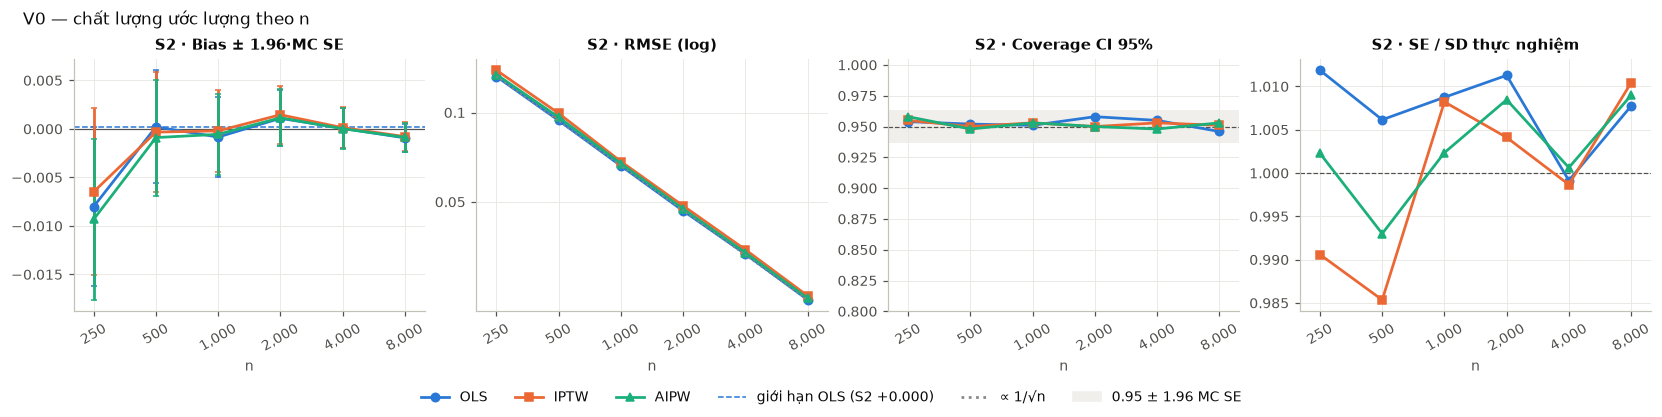

Mốc V0, số dòng đạt / tổng: {'bias_trong_3_mc_se': '18/18', 'coverage_quanh_95': '18/18', 'se_sd_quanh_1': '18/18'}


In [9]:
raw_V0, diag_V0 = run_mc(simulate_V0, "V0", ANALYSES_V0)
summary_V0 = report("V0", raw_V0, diag_V0, LIMIT_V0)

# Mốc Monte Carlo: dung sai theo MC SE, không ép bias bằng 0. Naive chệch theo DGP nên không xét.
base = summary_V0[summary_V0.method.isin(ADJUSTED)].copy()
base["bias_trong_3_mc_se"] = base.bias.abs() <= 3*base.mc_se_bias
base["coverage_quanh_95"] = (base.coverage - .95).abs() <= 3*np.sqrt(.95*.05/base.valid_reps)
base["se_sd_quanh_1"] = base.se_sd_ratio.between(.9, 1.1)
checks = ["bias_trong_3_mc_se", "coverage_quanh_95", "se_sd_quanh_1"]
print("Mốc V0, số dòng đạt / tổng:", {c: f"{int(base[c].sum())}/{len(base)}" for c in checks})
if not base[checks].all(axis=None):
    display(base.loc[~base[checks].all(axis=1), ["n", "method", "bias", "mc_se_bias", "coverage", "se_sd_ratio"]].round(4))

**Nhận xét V0.**
- **Kỳ vọng:** OLS, IPTW, AIPW gần không chệch, coverage gần 0.95; Naive chệch khoảng +0.45.
- **Kết quả:** đúng như kỳ vọng. Giới hạn của Naive là +0.449; ba estimator điều chỉnh có bias trong khoảng −0.009 đến +0.001, coverage 0.946–0.958, SE/SD 0.985–1.012. Cả 18 dòng đều đạt ba kiểm tra (bias trong 3 MC SE, coverage trong 3 MC SE quanh 0.95, SE/SD trong 0.9–1.1). RMSE giảm theo 1/√n, từ 0.132 (OLS, n = 250) xuống 0.023 (n = 8000); IPTW chỉ cao hơn OLS khoảng 5% vì ESS/n khoảng 0.87.
- **Giải thích:** đây là mốc. Tập biến đủ và đúng dạng nên mọi khác biệt ở các kịch bản sau đến từ X3. SD·√n theo FWL là 2.109, khớp SD thực nghiệm ở n = 8000 (0.0234 so với 0.0236).

## V1 — X3 là confounder

$$
\operatorname{logit} e(X) = \gamma_0 + 0.5X_1 + 0.5X_2 + \boldsymbol{0.5X_3},\qquad
\mu_0(X) = 0.5X_1 + 0.5X_2 + \boldsymbol{0.5X_3},\qquad \tau(X) = 2,\qquad \boldsymbol{X_3 \sim N(0,1)}
$$

X3 tác động lên cả A và Y. **S2** chính là trường hợp có confounder không quan sát được.

**Câu hỏi:** bỏ sót X3 chệch bao nhiêu, và kiểm tra balance có phát hiện được không?
**Kỳ vọng (pilot):** S2 có bias OLS ≈ **+0.237** và không giảm theo n, nên coverage về 0. S3 không chệch. Balance trên X1, X2 sau IPTW của S2 vẫn đẹp (|SMD| < 0.1).

In [10]:
def dgp_V1(n, rng):
    x1 = rng.normal(size=n)
    x2 = rng.normal(size=n)
    x3 = rng.normal(size=n)                     # KHÁC V0: thêm X3 ~ N(0,1)
    lin = 0.5*x1 + 0.5*x2 + 0.5*x3              # KHÁC V0: gamma3 = 0.5
    mu0 = 0.5*x1 + 0.5*x2 + 0.5*x3              # KHÁC V0: beta3 = 0.5
    tau = np.full(n, TAU)
    return {"X1": x1, "X2": x2, "X3": x3}, lin, mu0, tau


GAMMA0_V1 = gamma0_for(dgp_V1, target=0.5)


def simulate_V1(n, seed):
    return simulate(dgp_V1, GAMMA0_V1, n, seed)

In [11]:
FORMULA_V1 = {**FORMULA_V0, "X3": "N(0,1)", "logit e(X)": "γ0 + 0.5·X1 + 0.5·X2 + 0.5·X3",
              "μ0(X)": "0.5·X1 + 0.5·X2 + 0.5·X3"}
show_vs_base("V1", FORMULA_V1, dgp_V1, GAMMA0_V1)

**V1 so với V0** (◆ = khác, = giống)

,V0,V1,khác
X3,không có,"N(0,1)",◆
logit e(X),γ0 + 0.5·X1 + 0.5·X2,γ0 + 0.5·X1 + 0.5·X2 + 0.5·X3,◆
μ0(X),0.5·X1 + 0.5·X2,0.5·X1 + 0.5·X2 + 0.5·X3,◆
τ(X),2,2,=
P(A=1) mục tiêu,0.5,0.5,=
γ0,-0.0012,-0.0028,◆
P(A=1) trên mẫu tham chiếu,0.5000,0.5000,=
Var[X3],không có X3,0.996,◆
"Corr(X1, X3)",không có X3,-0.001,◆
ESS/n kỳ vọng (e thật),0.88,0.81,◆


Kiểm tra V1: τ = 2, P(A=1) ≈ 0.5, Var[X3] ≈ 1: PASS


In [12]:
LIMIT_V1 = large_sample_check(simulate_V1, dgp_V1, GAMMA0_V1, pilot={("S2", "Naive"): .64, ("S2", "OLS"): .237, ("S3", "OLS"): 0.})
show_fwl("V1", dgp_V1, GAMMA0_V1, LIMIT_V1)

**Một mẫu n = 2,000,000** — P(A=1) = 0.500

ước lượng    bias      SE  bias lý thuyết    lệch
analysis method                                                   
S2       Naive      2.6431  0.6431  0.0018          0.6439 -0.0008
         OLS        2.2356  0.2356  0.0016          0.2357 -0.0002
         IPTW       2.2366  0.2366  0.0017          0.2364  0.0002
         AIPW       2.2362  0.2362  0.0017          0.2361  0.0001
S3       OLS        2.0005  0.0005  0.0015          0.0000  0.0005
         IPTW       2.0012  0.0012  0.0017          0.0000  0.0012
         AIPW       2.0005  0.0005  0.0016          0.0000  0.0005

,ESS/n,e min,e max,trọng số lớn nhất,max |SMD| trước,max |SMD| sau IPTW,SMD X3 sau IPTW
S2,0.889,0.035,0.968,31.601,0.44,0.001,0.482
S3,0.817,0.015,0.984,36.909,0.44,0.001,0.001


Lệch lớn nhất so với lý thuyết: 0.0012
Pilot README, Naive S2: +0.640; mẫu lớn +0.6431
Pilot README, OLS S2: +0.237; mẫu lớn +0.2356
Pilot README, OLS S3: +0.000; mẫu lớn +0.0005


**V1: cơ chế OLS theo FWL** (mẫu tham chiếu; SD ở n = 2000 = SD·√n / √2000)

,SD(Ã),σ_res,SD·√n,bias FWL,SD ở n = 2000,bias mẫu lớn
S2,0.4763,1.1119,2.3342,0.2357,0.0522,0.2356
S3,0.4641,1.0000,2.1546,0.0000,0.0482,0.0005


### Balance V1: S2 cân bằng đẹp nhưng vẫn chệch

Một mẫu n = 2000. Mỗi hàng là một biến: chấm rỗng là |SMD| trước khi cân bằng, chấm đặc là sau IPTW với PS của tập biến đó.

Người phân tích dùng **S2** chỉ thấy hai hàng X1, X2. Hàng X3 ở hình trái chỉ mô phỏng mới vẽ được, vì trong thực tế X3 không quan sát được.

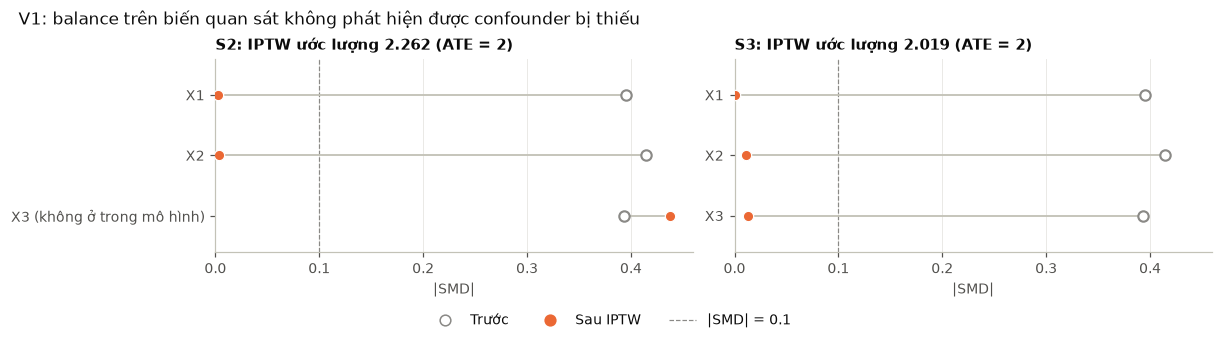

S2                         S3               
         |SMD| trước |SMD| sau IPTW |SMD| trước |SMD| sau IPTW
variable                                                      
X1             0.395          0.003       0.395          0.001
X2             0.414          0.003       0.414          0.011
X3             0.393          0.438       0.393          0.013

In [13]:
df_love, _ = simulate_V1(2000, SEED)
fig, axes = plt.subplots(1, 2, figsize=(11, 3), sharex=True, layout="constrained")
tables = {}
for ax, (analysis, cols) in zip(axes, ANALYSES.items()):
    design = make_design(df_love, cols)
    estimates, e, *_ = estimate_all(df_love, design)
    tables[analysis] = draw_love(ax, df_love, e, f"{analysis}: IPTW ước lượng {estimates['IPTW'][0]:.3f} (ATE = 2)", cols)
fig.legend(handles=LOVE_HANDLES, loc="outside lower center", ncol=3)
fig.suptitle("V1: balance trên biến quan sát không phát hiện được confounder bị thiếu", x=0.01, ha="left")
fig.savefig(FIG_DIR / "V1_balance.png", bbox_inches="tight")
plt.show()
display(pd.concat(tables, axis=1).round(3))

V1: n=[250, 500, 1000, 2000, 4000, 8000], R=1000 — 84s


**V1, S2: bias, RMSE, coverage, SE/SD theo n** (R = 1000)

bias                 rmse               coverage               se_sd_ratio              
method    OLS   IPTW   AIPW    OLS   IPTW   AIPW      OLS   IPTW   AIPW         OLS   IPTW   AIPW
n                                                                                                
250     0.240  0.242  0.240  0.281  0.285  0.282    0.620  0.613  0.615       1.023  0.999  1.008
500     0.236  0.237  0.236  0.259  0.261  0.260    0.382  0.403  0.390       0.980  0.980  0.979
1000    0.240  0.241  0.240  0.251  0.252  0.251    0.096  0.116  0.112       1.005  0.987  0.993
2000    0.239  0.240  0.239  0.245  0.246  0.245    0.006  0.010  0.007       0.985  0.992  0.988
4000    0.236  0.237  0.236  0.239  0.240  0.239    0.000  0.000  0.000       0.984  0.978  0.978
8000    0.237  0.238  0.237  0.239  0.239  0.239    0.000  0.000  0.000       0.995  0.992  0.993

**V1, S3: bias, RMSE, coverage, SE/SD theo n** (R = 1000)

bias                 rmse               coverage               se_sd_ratio              
method    OLS   IPTW   AIPW    OLS   IPTW   AIPW      OLS   IPTW   AIPW         OLS   IPTW   AIPW
n                                                                                                
250     0.002  0.004  0.001  0.135  0.154  0.140    0.956  0.949  0.952       1.010  0.962  0.993
500    -0.001 -0.000 -0.001  0.097  0.108  0.101    0.950  0.950  0.940       0.993  0.973  0.985
1000    0.002  0.002  0.001  0.067  0.077  0.070    0.953  0.947  0.944       1.010  0.966  0.997
2000    0.002  0.001  0.002  0.049  0.054  0.050    0.944  0.944  0.947       0.982  0.974  0.984
4000    0.001  0.001  0.001  0.034  0.038  0.035    0.953  0.951  0.951       1.010  0.990  1.003
8000    0.000 -0.000 -0.000  0.024  0.026  0.025    0.944  0.946  0.940       0.998  1.005  0.995

**Chẩn đoán trung bình qua rep** (`x3_smd_after` chỉ mô phỏng mới đo được)

,,ess_ratio,e_min,e_max,max_weight,max_abs_smd_before,max_abs_smd_after,x3_smd_after,ps_failed_reps
analysis,n,,,,,,,,
S2,250,0.872,0.131,0.865,6.671,0.518,0.034,0.489,0
S3,250,0.792,0.080,0.919,9.447,0.554,0.059,0.001,0
S2,500,0.880,0.117,0.881,7.256,0.493,0.023,0.485,0
S3,500,0.804,0.070,0.930,10.547,0.519,0.041,0.001,0
S2,1000,0.886,0.104,0.894,7.759,0.477,0.016,0.487,0
S3,1000,0.811,0.059,0.940,11.543,0.497,0.028,0.000,0
S2,2000,0.887,0.093,0.907,8.620,0.465,0.011,0.487,0
S3,2000,0.811,0.050,0.950,13.561,0.479,0.020,-0.001,0
S2,4000,0.887,0.082,0.917,9.520,0.459,0.008,0.483,0


**SD(S3) / SD(S2) theo n**

method,OLS,IPTW,AIPW
n,,,
250,0.935,1.016,0.951
500,0.912,0.995,0.933
1000,0.918,1.004,0.933
2000,0.926,1.008,0.944
4000,0.899,0.976,0.914
8000,0.920,0.976,0.937


S2: bias OLS (MC) nằm trong 3 SE quanh giới hạn +0.2356 ở 6/6 giá trị n
S2: SD OLS ở n = 8,000: MC 0.0262, FWL 0.0261
S3: bias OLS (MC) nằm trong 3 SE quanh giới hạn +0.0005 ở 6/6 giá trị n
S3: SD OLS ở n = 8,000: MC 0.0241, FWL 0.0241


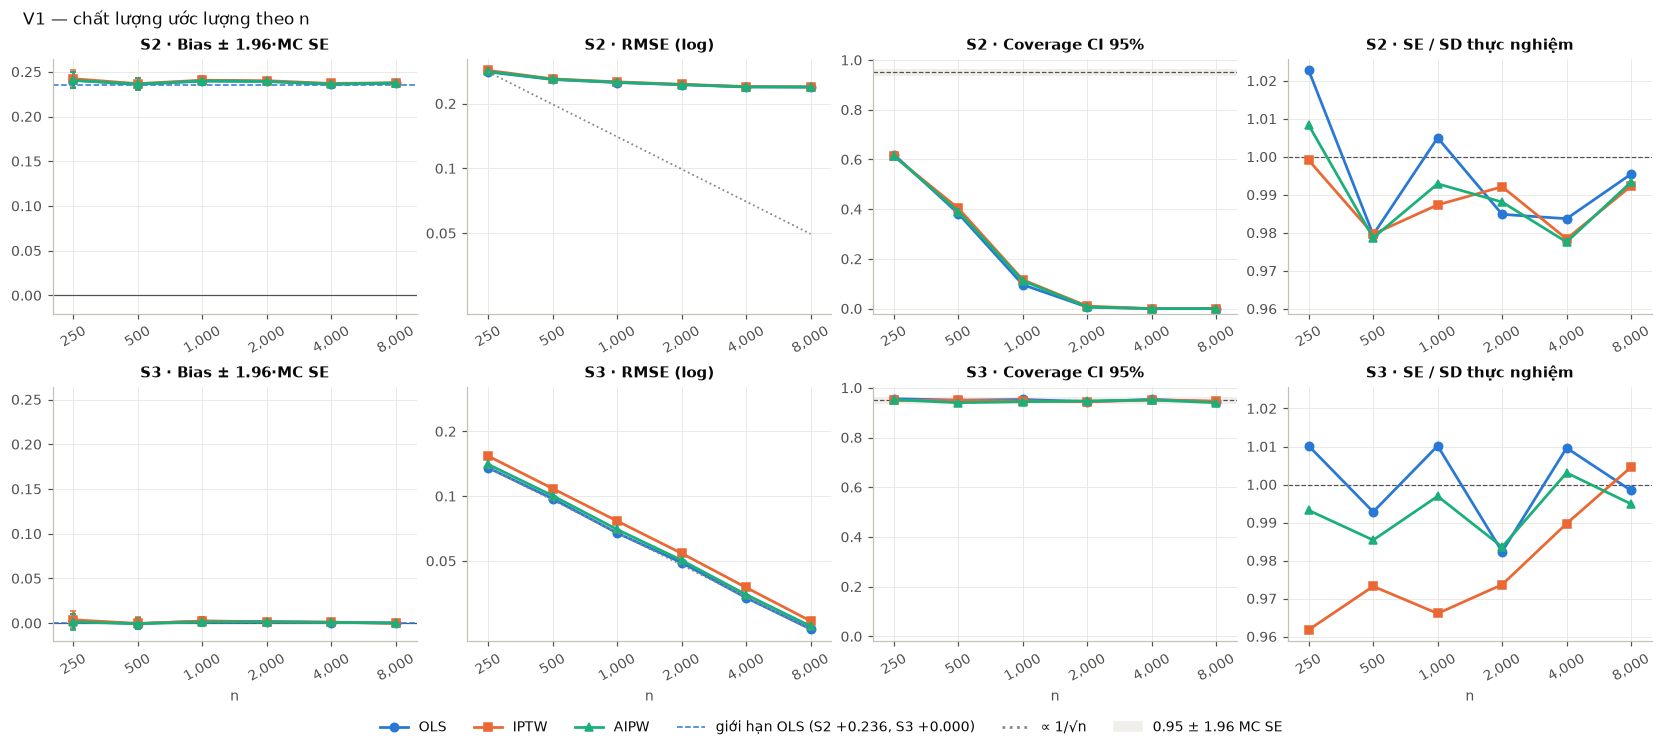

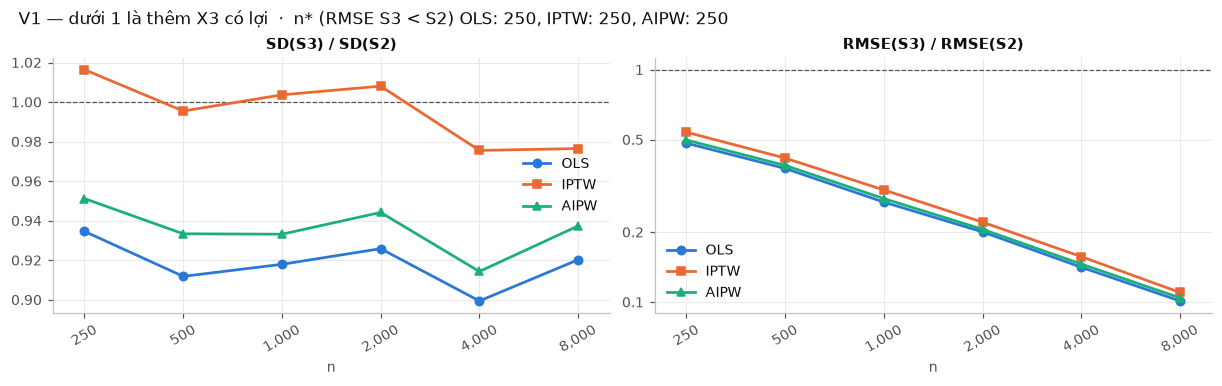

In [14]:
raw_V1, diag_V1 = run_mc(simulate_V1, "V1")
summary_V1 = report("V1", raw_V1, diag_V1, LIMIT_V1)

**Nhận xét V1.**
- **Kỳ vọng:** S2 chệch khoảng +0.237, coverage về 0; S3 không chệch; balance của S2 vẫn đẹp.
- **Kết quả:** S2 có bias +0.236 đến +0.242 ở cả ba estimator và mọi n, khớp giới hạn +0.236 và công thức FWL +0.236. Coverage của OLS giảm từ 0.620 (n = 250) xuống **0.000** từ n = 4000. S3 có bias ≤ 0.004, coverage 0.94–0.96. S3 thắng về RMSE ngay từ n = 250 (OLS: 0.135 so với 0.281); ở n = 8000 RMSE của S2 gấp khoảng 10 lần (0.239 so với 0.024).
- **Giải thích:** bias của S2 không giảm theo n nên CI càng hẹp càng bỏ lỡ ATE. IPTW và AIPW không cứu được vì PS và outcome cùng thiếu X3. **Balance không phát hiện được lỗi này:** max |SMD| trên X1, X2 sau IPTW giảm từ 0.034 xuống 0.006, trong khi SMD của X3 giữ ở khoảng 0.49 ở mọi n, mà người phân tích không đo được con số này. Đưa X3 vào còn có lợi về SD với OLS (S3/S2 = 0.90–0.94), vì X3 cũng giải thích Y. Với IPTW lợi đó gần như mất hết (0.98–1.02), vì ESS/n giảm từ 0.89 xuống 0.81.

## V2 — X3 chỉ tác động lên Y

$$
\operatorname{logit} e(X) = \gamma_0 + 0.5X_1 + 0.5X_2,\qquad
\mu_0(X) = 0.5X_1 + 0.5X_2 + \boldsymbol{0.5X_3},\qquad \tau(X) = 2
$$

X3 không ảnh hưởng tới A nên không gây nhiễu. Nó chỉ giải thích một phần phương sai của Y.

**Câu hỏi:** đưa biến tiên lượng vào có giúp giảm phương sai không?
**Kỳ vọng (pilot):** S2 và S3 đều không chệch; SD của OLS giảm 0.053 → **0.046**, khoảng 12%.

In [15]:
def dgp_V2(n, rng):
    x1 = rng.normal(size=n)
    x2 = rng.normal(size=n)
    x3 = rng.normal(size=n)                     # KHÁC V0: thêm X3 ~ N(0,1)
    lin = 0.5*x1 + 0.5*x2                       # gamma3 = 0: X3 không vào PS
    mu0 = 0.5*x1 + 0.5*x2 + 0.5*x3              # KHÁC V0: beta3 = 0.5
    tau = np.full(n, TAU)
    return {"X1": x1, "X2": x2, "X3": x3}, lin, mu0, tau


GAMMA0_V2 = gamma0_for(dgp_V2, target=0.5)


def simulate_V2(n, seed):
    return simulate(dgp_V2, GAMMA0_V2, n, seed)

In [16]:
show_vs_base("V2", {**FORMULA_V0, "X3": "N(0,1)", "μ0(X)": "0.5·X1 + 0.5·X2 + 0.5·X3"}, dgp_V2, GAMMA0_V2)

**V2 so với V0** (◆ = khác, = giống)

,V0,V2,khác
X3,không có,"N(0,1)",◆
logit e(X),γ0 + 0.5·X1 + 0.5·X2,γ0 + 0.5·X1 + 0.5·X2,=
μ0(X),0.5·X1 + 0.5·X2,0.5·X1 + 0.5·X2 + 0.5·X3,◆
τ(X),2,2,=
P(A=1) mục tiêu,0.5,0.5,=
γ0,-0.0012,-0.0012,=
P(A=1) trên mẫu tham chiếu,0.5000,0.5000,=
Var[X3],không có X3,0.996,◆
"Corr(X1, X3)",không có X3,-0.001,◆
ESS/n kỳ vọng (e thật),0.88,0.88,=


Kiểm tra V2: τ = 2, P(A=1) ≈ 0.5, Var[X3] ≈ 1: PASS


In [17]:
LIMIT_V2 = large_sample_check(simulate_V2, dgp_V2, GAMMA0_V2, pilot={("S2", "Naive"): .45, ("S2", "OLS"): 0., ("S3", "OLS"): 0.})
show_fwl("V2", dgp_V2, GAMMA0_V2, LIMIT_V2)

**Một mẫu n = 2,000,000** — P(A=1) = 0.500

ước lượng    bias      SE  bias lý thuyết    lệch
analysis method                                                   
S2       Naive      2.4483  0.4483  0.0018          0.4489 -0.0006
         OLS        2.0013  0.0013  0.0017          0.0000  0.0013
         IPTW       2.0015  0.0015  0.0017          0.0000  0.0015
         AIPW       2.0014  0.0014  0.0017          0.0000  0.0014
S3       OLS        2.0016  0.0016  0.0015          0.0000  0.0016
         IPTW       2.0018  0.0018  0.0015          0.0000  0.0018
         AIPW       2.0018  0.0018  0.0015          0.0000  0.0018

,ESS/n,e min,e max,trọng số lớn nhất,max |SMD| trước,max |SMD| sau IPTW,SMD X3 sau IPTW
S2,0.877,0.03,0.973,37.501,0.46,0.0,-0.001
S3,0.877,0.03,0.973,37.512,0.46,0.0,0.000


Lệch lớn nhất so với lý thuyết: 0.0018
Pilot README, Naive S2: +0.450; mẫu lớn +0.4483
Pilot README, OLS S2: +0.000; mẫu lớn +0.0013
Pilot README, OLS S3: +0.000; mẫu lớn +0.0016


**V2: cơ chế OLS theo FWL** (mẫu tham chiếu; SD ở n = 2000 = SD·√n / √2000)

,SD(Ã),σ_res,SD·√n,bias FWL,SD ở n = 2000,bias mẫu lớn
S2,0.4741,1.1175,2.3570,0.0,0.0527,0.0013
S3,0.4741,1.0000,2.1091,0.0,0.0472,0.0016


V2: n=[250, 500, 1000, 2000, 4000, 8000], R=1000 — 85s


**V2, S2: bias, RMSE, coverage, SE/SD theo n** (R = 1000)

bias                 rmse               coverage               se_sd_ratio              
method    OLS   IPTW   AIPW    OLS   IPTW   AIPW      OLS   IPTW   AIPW         OLS   IPTW   AIPW
n                                                                                                
250     0.002  0.005  0.003  0.151  0.156  0.153    0.945  0.944  0.947       0.987  0.976  0.982
500    -0.002 -0.001 -0.002  0.107  0.111  0.109    0.948  0.948  0.948       0.984  0.975  0.978
1000    0.003  0.005  0.004  0.075  0.078  0.076    0.954  0.943  0.943       1.000  0.983  0.993
2000    0.002  0.001  0.002  0.053  0.054  0.053    0.945  0.950  0.949       0.999  1.003  1.001
4000    0.001  0.002  0.002  0.038  0.039  0.039    0.948  0.945  0.942       0.985  0.977  0.975
8000   -0.000  0.000 -0.000  0.027  0.028  0.027    0.950  0.955  0.952       0.985  0.976  0.981

**V2, S3: bias, RMSE, coverage, SE/SD theo n** (R = 1000)

bias                 rmse               coverage               se_sd_ratio              
method    OLS   IPTW   AIPW    OLS   IPTW   AIPW      OLS   IPTW   AIPW         OLS   IPTW   AIPW
n                                                                                                
250     0.003  0.005  0.003  0.134  0.141  0.137    0.942  0.944  0.949       1.001  0.981  0.987
500     0.001  0.002  0.001  0.095  0.099  0.097    0.956  0.953  0.951       0.995  0.986  0.986
1000    0.003  0.004  0.003  0.068  0.071  0.069    0.946  0.930  0.936       0.983  0.970  0.979
2000    0.001  0.000  0.001  0.046  0.048  0.047    0.953  0.957  0.959       1.024  1.031  1.023
4000    0.001  0.001  0.001  0.034  0.035  0.035    0.950  0.942  0.942       0.986  0.979  0.977
8000   -0.000  0.001  0.000  0.024  0.025  0.024    0.949  0.948  0.943       0.994  0.982  0.985

**Chẩn đoán trung bình qua rep** (`x3_smd_after` chỉ mô phỏng mới đo được)

,,ess_ratio,e_min,e_max,max_weight,max_abs_smd_before,max_abs_smd_after,x3_smd_after,ps_failed_reps
analysis,n,,,,,,,,
S2,250,0.860,0.122,0.879,7.185,0.536,0.037,-0.000,0
S3,250,0.854,0.118,0.884,7.364,0.536,0.041,0.001,0
S2,500,0.869,0.108,0.892,7.677,0.513,0.025,-0.006,0
S3,500,0.866,0.106,0.894,7.797,0.513,0.028,0.000,0
S2,1000,0.871,0.093,0.906,8.530,0.498,0.018,0.003,0
S3,1000,0.870,0.092,0.907,8.592,0.498,0.020,0.000,0
S2,2000,0.873,0.082,0.918,9.625,0.488,0.013,0.002,0
S3,2000,0.872,0.081,0.918,9.669,0.488,0.014,0.000,0
S2,4000,0.874,0.072,0.927,10.545,0.481,0.009,0.002,0


**SD(S3) / SD(S2) theo n**

method,OLS,IPTW,AIPW
n,,,
250,0.884,0.902,0.890
500,0.886,0.893,0.888
1000,0.910,0.913,0.907
2000,0.873,0.877,0.875
4000,0.893,0.899,0.892
8000,0.886,0.895,0.891


S2: bias OLS (MC) nằm trong 3 SE quanh giới hạn +0.0013 ở 6/6 giá trị n
S2: SD OLS ở n = 8,000: MC 0.0268, FWL 0.0264
S3: bias OLS (MC) nằm trong 3 SE quanh giới hạn +0.0016 ở 6/6 giá trị n
S3: SD OLS ở n = 8,000: MC 0.0237, FWL 0.0236


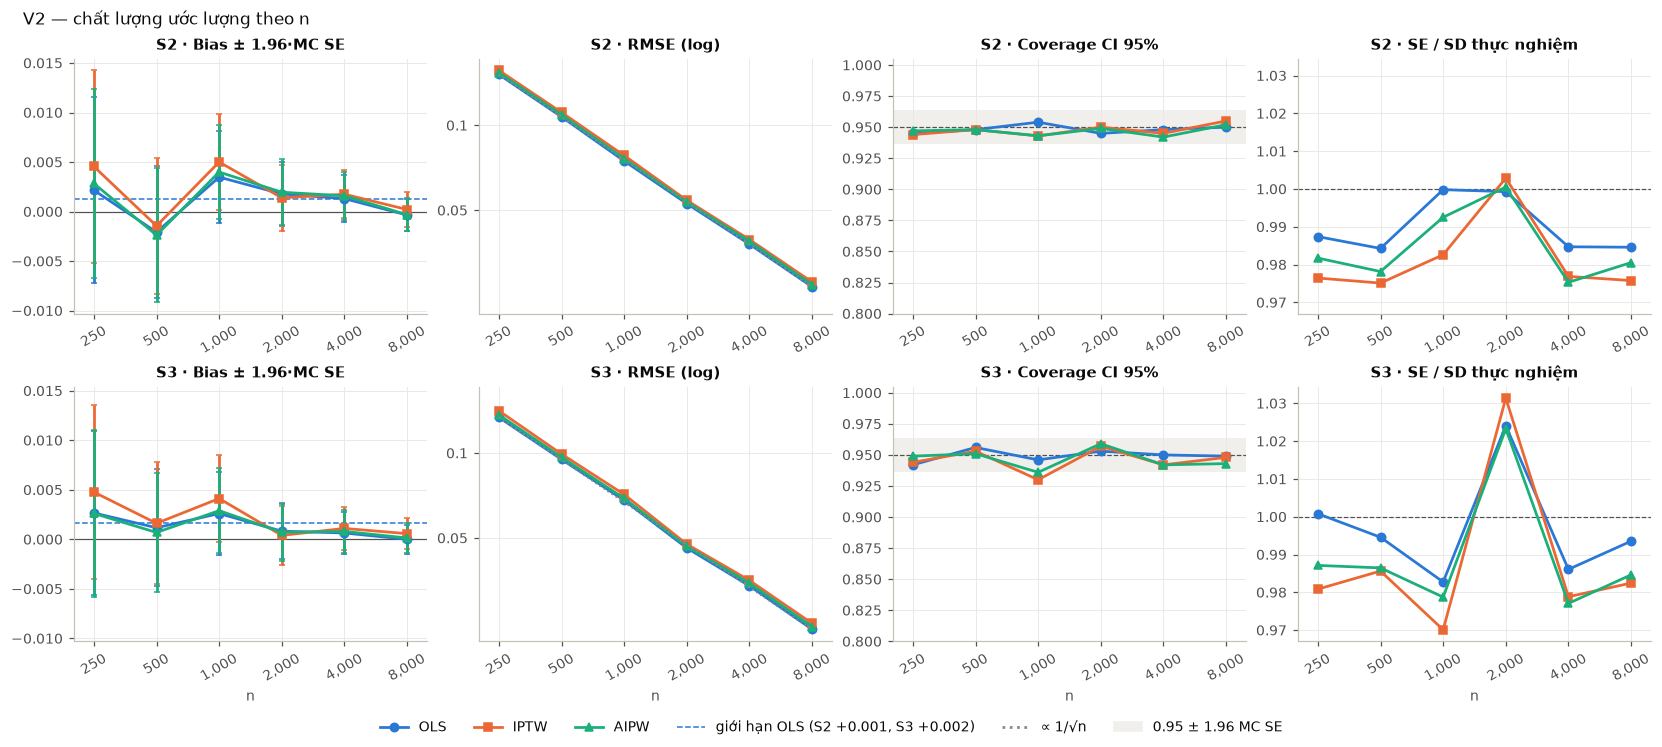

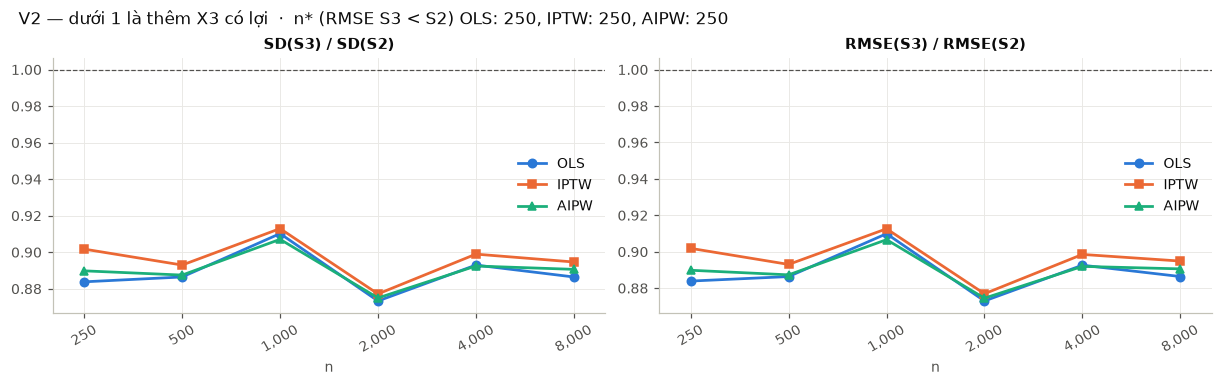

In [18]:
raw_V2, diag_V2 = run_mc(simulate_V2, "V2")
summary_V2 = report("V2", raw_V2, diag_V2, LIMIT_V2)

**Nhận xét V2.**
- **Kỳ vọng:** không chệch; SD của OLS giảm khoảng 12%.
- **Kết quả:** cả hai tập biến có bias ≤ 0.005, coverage 0.93–0.96. SD(S3)/SD(S2) của OLS là 0.87–0.91 tùy n, IPTW và AIPW tương tự. Công thức FWL cho 0.895, tức giảm khoảng **10.5%**. Số 12% của pilot (0.053 → 0.046) đúng với n = 2000 (0.873 ở đây) nhưng hơi lạc quan so với mức chung. S3 thắng về RMSE từ n = 250 (OLS: 0.134 so với 0.151).
- **Giải thích:** X3 không vào PS nên SD(Ã) giữ nguyên 0.474 và ESS/n giữ khoảng 0.87. Lợi ích đến hoàn toàn từ σ_res, giảm từ √1.25 = 1.118 xuống 1. Đây là trường hợp đưa biến vào không mất gì, kể cả với IPTW: IPTW không cần X3 để cân bằng, nhưng cũng không bị hại vì hệ số của X3 trong PS gần 0. Lợi ích của IPTW ở đây đến từ chính sự mất cân bằng ngẫu nhiên của X3 được điều chỉnh trong mẫu.

## V3 — X3 chỉ tác động lên A

$$
\operatorname{logit} e(X) = \gamma_0 + 0.5X_1 + 0.5X_2 + \boldsymbol{1.0X_3},\qquad
\mu_0(X) = 0.5X_1 + 0.5X_2,\qquad \tau(X) = 2
$$

X3 giống một instrument: làm thay đổi A nhưng không liên quan tới Y. Vì τ hằng số và không có confounder ẩn, bỏ X3 không gây chệch.

**Câu hỏi:** đưa một biến chỉ tác động lên A vào có hại không?
**Kỳ vọng (pilot):** cả hai không chệch; SD của OLS tăng 0.047 → **0.054**, khoảng 15%; ESS/n của IPTW giảm từ 0.88 xuống 0.64.

In [19]:
def dgp_V3(n, rng):
    x1 = rng.normal(size=n)
    x2 = rng.normal(size=n)
    x3 = rng.normal(size=n)                     # KHÁC V0: thêm X3 ~ N(0,1)
    lin = 0.5*x1 + 0.5*x2 + 1.0*x3              # KHÁC V0: gamma3 = 1.0
    mu0 = 0.5*x1 + 0.5*x2                       # beta3 = 0: X3 không vào outcome
    tau = np.full(n, TAU)
    return {"X1": x1, "X2": x2, "X3": x3}, lin, mu0, tau


GAMMA0_V3 = gamma0_for(dgp_V3, target=0.5)


def simulate_V3(n, seed):
    return simulate(dgp_V3, GAMMA0_V3, n, seed)

In [20]:
show_vs_base("V3", {**FORMULA_V0, "X3": "N(0,1)", "logit e(X)": "γ0 + 0.5·X1 + 0.5·X2 + 1.0·X3"}, dgp_V3, GAMMA0_V3)

**V3 so với V0** (◆ = khác, = giống)

,V0,V3,khác
X3,không có,"N(0,1)",◆
logit e(X),γ0 + 0.5·X1 + 0.5·X2,γ0 + 0.5·X1 + 0.5·X2 + 1.0·X3,◆
μ0(X),0.5·X1 + 0.5·X2,0.5·X1 + 0.5·X2,=
τ(X),2,2,=
P(A=1) mục tiêu,0.5,0.5,=
γ0,-0.0012,-0.0042,◆
P(A=1) trên mẫu tham chiếu,0.5000,0.5000,=
Var[X3],không có X3,0.996,◆
"Corr(X1, X3)",không có X3,-0.001,◆
ESS/n kỳ vọng (e thật),0.88,0.64,◆


Kiểm tra V3: τ = 2, P(A=1) ≈ 0.5, Var[X3] ≈ 1: PASS


In [21]:
LIMIT_V3 = large_sample_check(simulate_V3, dgp_V3, GAMMA0_V3, pilot={("S2", "OLS"): 0., ("S3", "OLS"): 0.})
show_fwl("V3", dgp_V3, GAMMA0_V3, LIMIT_V3)

**Một mẫu n = 2,000,000** — P(A=1) = 0.499

ước lượng    bias      SE  bias lý thuyết    lệch
analysis method                                                   
S2       Naive      2.3836  0.3836  0.0017          0.3855 -0.0019
         OLS        1.9983 -0.0017  0.0015          0.0000 -0.0017
         IPTW       1.9989 -0.0011  0.0015          0.0005 -0.0016
         AIPW       1.9984 -0.0016  0.0015          0.0000 -0.0016
S3       OLS        1.9984 -0.0016  0.0016          0.0000 -0.0016
         IPTW       1.9982 -0.0018  0.0019          0.0000 -0.0018
         AIPW       1.9981 -0.0019  0.0018          0.0000 -0.0019

,ESS/n,e min,e max,trọng số lớn nhất,max |SMD| trước,max |SMD| sau IPTW,SMD X3 sau IPTW
S2,0.914,0.052,0.953,21.223,0.393,0.001,0.902
S3,0.643,0.003,0.998,147.083,0.834,0.001,0.001


Lệch lớn nhất so với lý thuyết: 0.0019
Pilot README, OLS S2: +0.000; mẫu lớn -0.0017
Pilot README, OLS S3: +0.000; mẫu lớn -0.0016


**V3: cơ chế OLS theo FWL** (mẫu tham chiếu; SD ở n = 2000 = SD·√n / √2000)

,SD(Ã),σ_res,SD·√n,bias FWL,SD ở n = 2000,bias mẫu lớn
S2,0.4810,1.0,2.0788,0.0,0.0465,-0.0017
S3,0.4409,1.0,2.2680,0.0,0.0507,-0.0016


### Overlap V3: S2 so với S3

Cùng dữ liệu, chỉ khác PS ước lượng bằng tập biến nào (mẫu n = 200.000). Đường viền là phân phối ê(X) theo nhóm; phần tô xám là vùng overlap, hệ số overlap là diện tích của nó (1 = trùng hoàn toàn).

Đưa X3 vào làm PS tách mạnh hai nhóm, nhưng phần tách thêm đó không liên quan gì tới Y. IPTW phải trả giá bằng trọng số lớn hơn mà không đổi lại được gì.

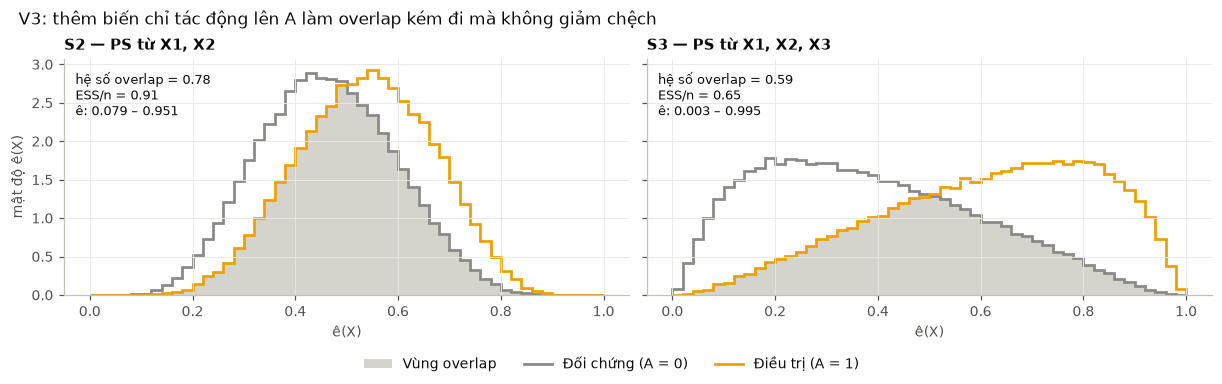

,hệ số overlap,ESS/n,ê min,ê max,trọng số lớn nhất
S2,0.777,0.914,0.079,0.951,11.829
S3,0.594,0.652,0.003,0.995,72.947


In [22]:
df_ref, _ = simulate_V3(N_REF, 1)
a_ref = df_ref.A.to_numpy()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True, layout="constrained")
rows = {}
for ax, (analysis, cols) in zip(axes, ANALYSES.items()):
    e_fit = fit_propensity(a_ref, make_design(df_ref, cols))
    rows[analysis] = draw_ps_overlap(ax, e_fit, a_ref, f"{analysis} — PS từ {', '.join(cols)}")
axes[0].set_ylabel("mật độ ê(X)")
handles, labels = axes[1].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=3)
fig.suptitle("V3: thêm biến chỉ tác động lên A làm overlap kém đi mà không giảm chệch", x=0.01, ha="left")
fig.savefig(FIG_DIR / "V3_overlap.png", bbox_inches="tight")
plt.show()
display(pd.DataFrame(rows).T.round(3))

V3: n=[250, 500, 1000, 2000, 4000, 8000], R=1000 — 89s


**V3, S2: bias, RMSE, coverage, SE/SD theo n** (R = 1000)

bias                 rmse               coverage               se_sd_ratio              
method    OLS   IPTW   AIPW    OLS   IPTW   AIPW      OLS   IPTW   AIPW         OLS   IPTW   AIPW
n                                                                                                
250     0.007  0.010  0.007  0.132  0.137  0.134    0.942  0.941  0.941       0.998  0.979  0.987
500     0.001  0.003  0.001  0.093  0.095  0.094    0.952  0.950  0.952       0.999  0.992  0.996
1000    0.002  0.003  0.002  0.066  0.068  0.067    0.952  0.947  0.953       0.991  0.984  0.989
2000    0.002  0.002  0.001  0.046  0.046  0.046    0.957  0.956  0.955       1.018  1.018  1.016
4000   -0.002 -0.001 -0.002  0.033  0.034  0.033    0.953  0.958  0.955       1.000  0.997  0.994
8000    0.001  0.002  0.001  0.023  0.023  0.023    0.950  0.953  0.957       1.033  1.037  1.037

**V3, S3: bias, RMSE, coverage, SE/SD theo n** (R = 1000)

bias                 rmse               coverage               se_sd_ratio              
method    OLS   IPTW   AIPW    OLS   IPTW   AIPW      OLS   IPTW   AIPW         OLS   IPTW   AIPW
n                                                                                                
250     0.009  0.020  0.011  0.146  0.176  0.160    0.938  0.920  0.934       0.990  0.897  0.959
500     0.001  0.003 -0.000  0.106  0.125  0.117    0.943  0.925  0.933       0.961  0.924  0.935
1000    0.003  0.003  0.003  0.072  0.087  0.079    0.944  0.935  0.941       0.994  0.949  0.991
2000    0.002  0.004  0.003  0.050  0.060  0.055    0.953  0.948  0.951       1.014  0.995  1.014
4000   -0.002 -0.002 -0.002  0.036  0.043  0.039    0.951  0.950  0.949       1.003  0.979  1.002
8000    0.001  0.001  0.002  0.025  0.029  0.026    0.954  0.945  0.952       1.034  1.032  1.064

**Chẩn đoán trung bình qua rep** (`x3_smd_after` chỉ mô phỏng mới đo được)

,,ess_ratio,e_min,e_max,max_weight,max_abs_smd_before,max_abs_smd_after,x3_smd_after,ps_failed_reps
analysis,n,,,,,,,,
S2,250,0.901,0.163,0.835,5.722,0.459,0.026,0.905,0
S3,250,0.659,0.034,0.965,14.688,0.840,0.112,0.019,0
S2,500,0.906,0.143,0.856,6.158,0.448,0.019,0.904,0
S3,500,0.647,0.026,0.974,18.602,0.836,0.083,0.004,0
S2,1000,0.910,0.131,0.867,6.578,0.430,0.013,0.904,0
S3,1000,0.644,0.021,0.980,22.739,0.836,0.060,-0.001,0
S2,2000,0.911,0.118,0.881,7.170,0.420,0.009,0.905,0
S3,2000,0.645,0.016,0.984,26.851,0.837,0.042,0.002,0
S2,4000,0.913,0.108,0.892,7.827,0.411,0.006,0.903,0


**SD(S3) / SD(S2) theo n**

method,OLS,IPTW,AIPW
n,,,
250,1.100,1.286,1.191
500,1.135,1.311,1.252
1000,1.088,1.287,1.185
2000,1.097,1.280,1.192
4000,1.088,1.295,1.185
8000,1.089,1.273,1.162


S2: bias OLS (MC) nằm trong 3 SE quanh giới hạn -0.0017 ở 6/6 giá trị n
S2: SD OLS ở n = 8,000: MC 0.0225, FWL 0.0232
S3: bias OLS (MC) nằm trong 3 SE quanh giới hạn -0.0016 ở 6/6 giá trị n
S3: SD OLS ở n = 8,000: MC 0.0245, FWL 0.0254


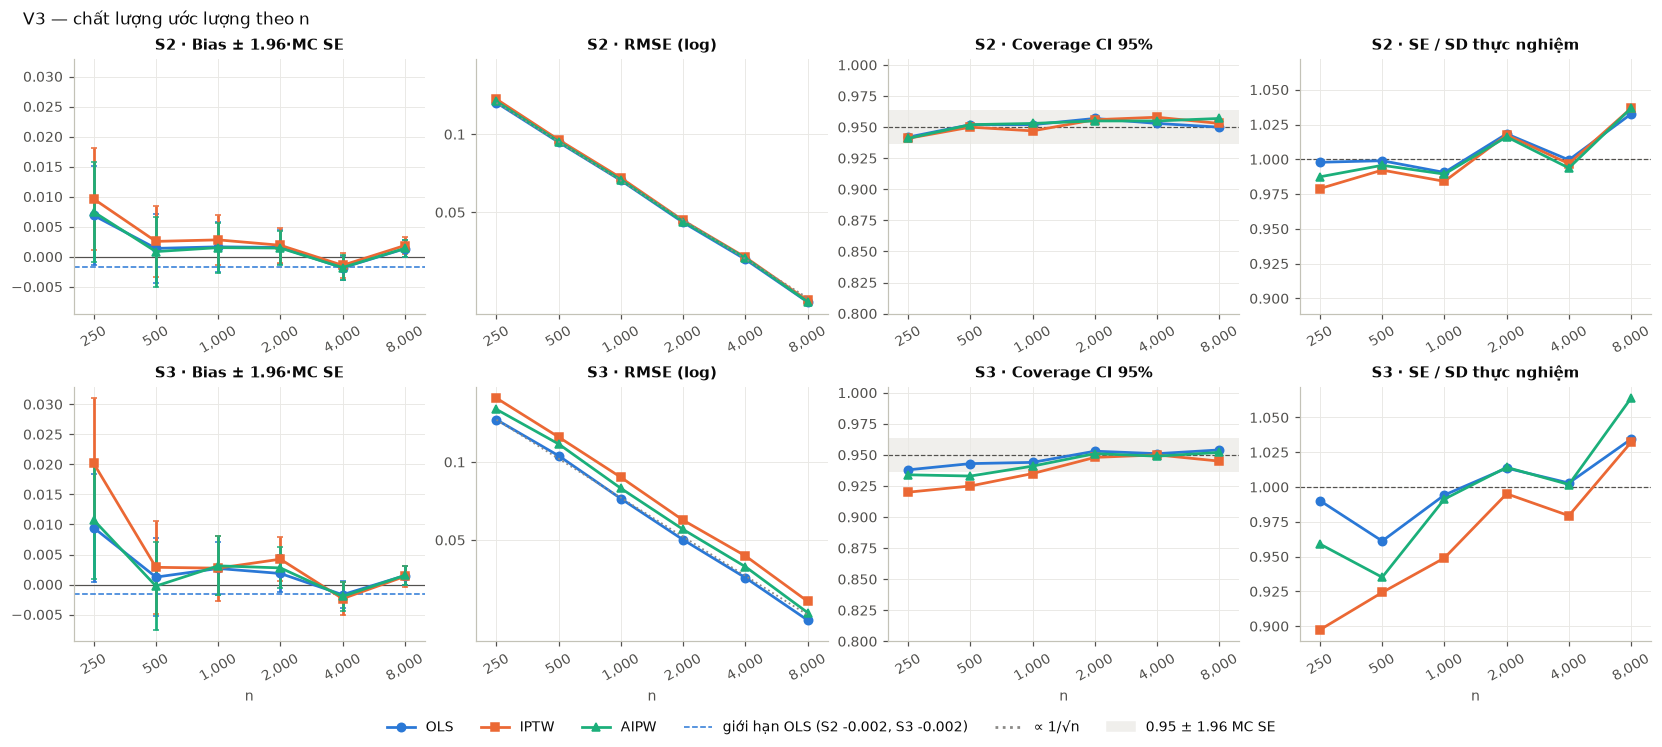

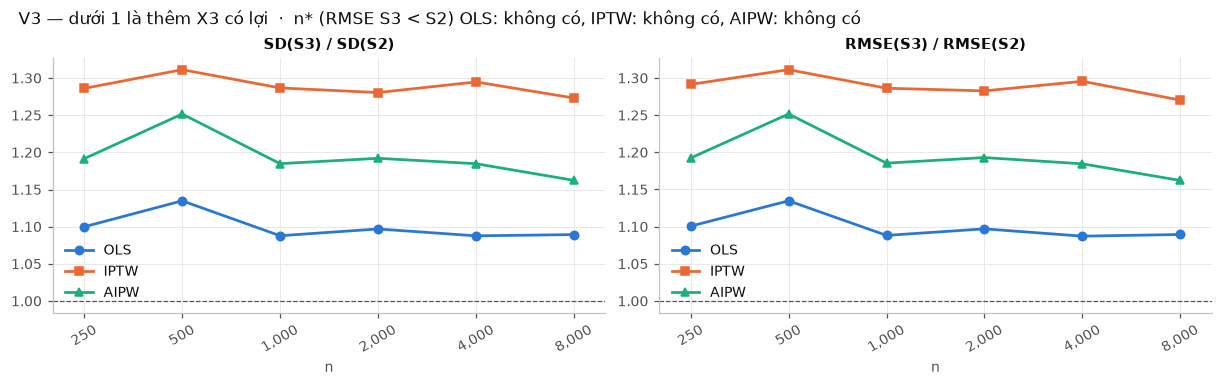

In [23]:
raw_V3, diag_V3 = run_mc(simulate_V3, "V3")
summary_V3 = report("V3", raw_V3, diag_V3, LIMIT_V3)

**Nhận xét V3.**
- **Kỳ vọng:** không chệch; SD của OLS tăng khoảng 15%; ESS/n của IPTW giảm từ 0.88 xuống 0.64.
- **Kết quả:** không có bias đáng kể, trừ IPTW của S3 ở n = 250 (+0.020, khoảng 3.6 MC SE), đã về ≤ 0.004 từ n = 500. SD tăng theo mức khác nhau: OLS **1.09–1.14** lần, AIPW **1.16–1.25** lần, IPTW **1.27–1.31** lần. FWL cho OLS 1.091, nên số 15% của pilot hơi cao. ESS/n giảm từ 0.91 xuống **0.64**; ở n = 8000, ê nhỏ nhất trung bình giảm từ 0.097 xuống 0.010 và trọng số lớn nhất tăng từ 8.4 lên 39.6. Coverage của IPTW S3 chỉ 0.920–0.925 ở n ≤ 500 (SE/SD 0.90–0.92), về 0.95 từ n = 2000. S3 thua S2 về RMSE ở mọi n và mọi estimator (n = 250, IPTW: 0.176 so với 0.137).
- **Giải thích:** X3 không giải thích Y nên σ_res giữ nguyên 1, nhưng X3 giải thích A nên SD(Ã) giảm từ 0.481 xuống 0.441: OLS còn ít biến thiên của A để so sánh. Với IPTW giá phải trả lớn hơn, vì trọng số đi thẳng vào phương sai và không có mô hình outcome bù lại. AIPW nằm giữa. S2 không chệch dù SMD của X3 sau IPTW khoảng 0.90: mất cân bằng trên một biến không liên quan tới Y thì vô hại. Nghĩa là **balance xấu trên X3 không phải là lý do để đưa X3 vào**; điều quyết định là X3 có liên quan tới Y hay không.

## V4 — X3 không tác động gì (noise)

$$
\operatorname{logit} e(X) = \gamma_0 + 0.5X_1 + 0.5X_2,\qquad
\mu_0(X) = 0.5X_1 + 0.5X_2,\qquad \tau(X) = 2,\qquad \boldsymbol{X_3 \sim N(0,1)\ \text{độc lập}}
$$

DGP giống hệt **V0**, chỉ có thêm một cột nhiễu trong dữ liệu.

**Câu hỏi:** thêm một biến thừa tốn bao nhiêu?
**Kỳ vọng (pilot):** cả hai không chệch; SD gần như không đổi ở n = 2000, chi phí có thể thấy rõ hơn ở n nhỏ.

In [24]:
def dgp_V4(n, rng):
    x1 = rng.normal(size=n)
    x2 = rng.normal(size=n)
    x3 = rng.normal(size=n)                     # KHÁC V0: thêm cột X3, không vào PS và outcome
    lin = 0.5*x1 + 0.5*x2
    mu0 = 0.5*x1 + 0.5*x2
    tau = np.full(n, TAU)
    return {"X1": x1, "X2": x2, "X3": x3}, lin, mu0, tau


GAMMA0_V4 = gamma0_for(dgp_V4, target=0.5)


def simulate_V4(n, seed):
    return simulate(dgp_V4, GAMMA0_V4, n, seed)

In [25]:
show_vs_base("V4", {**FORMULA_V0, "X3": "N(0,1), độc lập"}, dgp_V4, GAMMA0_V4)

**V4 so với V0** (◆ = khác, = giống)

,V0,V4,khác
X3,không có,"N(0,1), độc lập",◆
logit e(X),γ0 + 0.5·X1 + 0.5·X2,γ0 + 0.5·X1 + 0.5·X2,=
μ0(X),0.5·X1 + 0.5·X2,0.5·X1 + 0.5·X2,=
τ(X),2,2,=
P(A=1) mục tiêu,0.5,0.5,=
γ0,-0.0012,-0.0012,=
P(A=1) trên mẫu tham chiếu,0.5000,0.5000,=
Var[X3],không có X3,0.996,◆
"Corr(X1, X3)",không có X3,-0.001,◆
ESS/n kỳ vọng (e thật),0.88,0.88,=


Kiểm tra V4: τ = 2, P(A=1) ≈ 0.5, Var[X3] ≈ 1: PASS


In [26]:
LIMIT_V4 = large_sample_check(simulate_V4, dgp_V4, GAMMA0_V4, pilot={("S2", "Naive"): .45, ("S2", "OLS"): 0., ("S3", "OLS"): 0.})
show_fwl("V4", dgp_V4, GAMMA0_V4, LIMIT_V4)

**Một mẫu n = 2,000,000** — P(A=1) = 0.500

ước lượng    bias      SE  bias lý thuyết    lệch
analysis method                                                   
S2       Naive      2.4489  0.4489  0.0017          0.4486  0.0003
         OLS        2.0016  0.0016  0.0015          0.0000  0.0016
         IPTW       2.0019  0.0019  0.0015          0.0000  0.0019
         AIPW       2.0018  0.0018  0.0015          0.0000  0.0018
S3       OLS        2.0016  0.0016  0.0015          0.0000  0.0016
         IPTW       2.0019  0.0019  0.0015          0.0000  0.0019
         AIPW       2.0018  0.0018  0.0015          0.0000  0.0018

,ESS/n,e min,e max,trọng số lớn nhất,max |SMD| trước,max |SMD| sau IPTW,SMD X3 sau IPTW
S2,0.877,0.03,0.973,37.501,0.46,0.0,-0.001
S3,0.877,0.03,0.973,37.512,0.46,0.0,0.000


Lệch lớn nhất so với lý thuyết: 0.0019
Pilot README, Naive S2: +0.450; mẫu lớn +0.4489
Pilot README, OLS S2: +0.000; mẫu lớn +0.0016
Pilot README, OLS S3: +0.000; mẫu lớn +0.0016


**V4: cơ chế OLS theo FWL** (mẫu tham chiếu; SD ở n = 2000 = SD·√n / √2000)

,SD(Ã),σ_res,SD·√n,bias FWL,SD ở n = 2000,bias mẫu lớn
S2,0.4741,1.0,2.1091,0.0,0.0472,0.0016
S3,0.4741,1.0,2.1091,0.0,0.0472,0.0016


V4: n=[250, 500, 1000, 2000, 4000, 8000], R=1000 — 88s


**V4, S2: bias, RMSE, coverage, SE/SD theo n** (R = 1000)

bias                 rmse               coverage               se_sd_ratio              
method    OLS   IPTW   AIPW    OLS   IPTW   AIPW      OLS   IPTW   AIPW         OLS   IPTW   AIPW
n                                                                                                
250     0.001 -0.000 -0.000  0.138  0.142  0.139    0.942  0.933  0.939       0.975  0.973  0.971
500     0.001  0.002  0.001  0.098  0.101  0.100    0.949  0.944  0.947       0.969  0.967  0.961
1000   -0.002 -0.001 -0.002  0.064  0.066  0.065    0.962  0.961  0.954       1.037  1.040  1.032
2000    0.002  0.003  0.003  0.048  0.050  0.049    0.946  0.936  0.945       0.991  0.977  0.987
4000   -0.001 -0.001 -0.001  0.033  0.035  0.034    0.939  0.943  0.939       0.996  0.996  0.995
8000    0.001  0.001  0.001  0.024  0.025  0.024    0.946  0.948  0.945       0.993  0.984  0.986

**V4, S3: bias, RMSE, coverage, SE/SD theo n** (R = 1000)

bias                 rmse               coverage               se_sd_ratio              
method    OLS   IPTW   AIPW    OLS   IPTW   AIPW      OLS   IPTW   AIPW         OLS   IPTW   AIPW
n                                                                                                
250     0.001  0.000 -0.000  0.138  0.143  0.140    0.941  0.933  0.932       0.975  0.970  0.965
500     0.000  0.002  0.001  0.098  0.101  0.100    0.944  0.944  0.947       0.968  0.964  0.959
1000   -0.002 -0.001 -0.002  0.065  0.066  0.066    0.964  0.962  0.954       1.036  1.038  1.030
2000    0.002  0.003  0.003  0.048  0.050  0.049    0.947  0.938  0.944       0.991  0.977  0.987
4000   -0.001 -0.001 -0.001  0.033  0.035  0.034    0.939  0.941  0.939       0.996  0.995  0.995
8000    0.001  0.001  0.001  0.024  0.025  0.024    0.945  0.949  0.944       0.993  0.984  0.986

**Chẩn đoán trung bình qua rep** (`x3_smd_after` chỉ mô phỏng mới đo được)

,,ess_ratio,e_min,e_max,max_weight,max_abs_smd_before,max_abs_smd_after,x3_smd_after,ps_failed_reps
analysis,n,,,,,,,,
S2,250,0.860,0.123,0.876,7.127,0.535,0.038,-0.003,0
S3,250,0.855,0.119,0.880,7.300,0.535,0.043,0.000,0
S2,500,0.865,0.106,0.895,7.853,0.517,0.027,-0.000,0
S3,500,0.863,0.103,0.897,7.937,0.517,0.029,0.000,0
S2,1000,0.871,0.094,0.907,8.490,0.499,0.017,-0.000,0
S3,1000,0.869,0.093,0.908,8.580,0.499,0.019,0.000,0
S2,2000,0.873,0.083,0.917,9.414,0.488,0.013,-0.001,0
S3,2000,0.872,0.082,0.917,9.455,0.488,0.014,-0.000,0
S2,4000,0.875,0.074,0.927,10.413,0.479,0.009,0.001,0


**SD(S3) / SD(S2) theo n**

method,OLS,IPTW,AIPW
n,,,
250,1.002,1.004,1.007
500,1.003,1.003,1.002
1000,1.002,1.003,1.003
2000,1.000,1.000,1.000
4000,1.000,1.000,1.000
8000,1.001,1.000,1.000


S2: bias OLS (MC) nằm trong 3 SE quanh giới hạn +0.0016 ở 6/6 giá trị n
S2: SD OLS ở n = 8,000: MC 0.0238, FWL 0.0236
S3: bias OLS (MC) nằm trong 3 SE quanh giới hạn +0.0016 ở 6/6 giá trị n
S3: SD OLS ở n = 8,000: MC 0.0238, FWL 0.0236


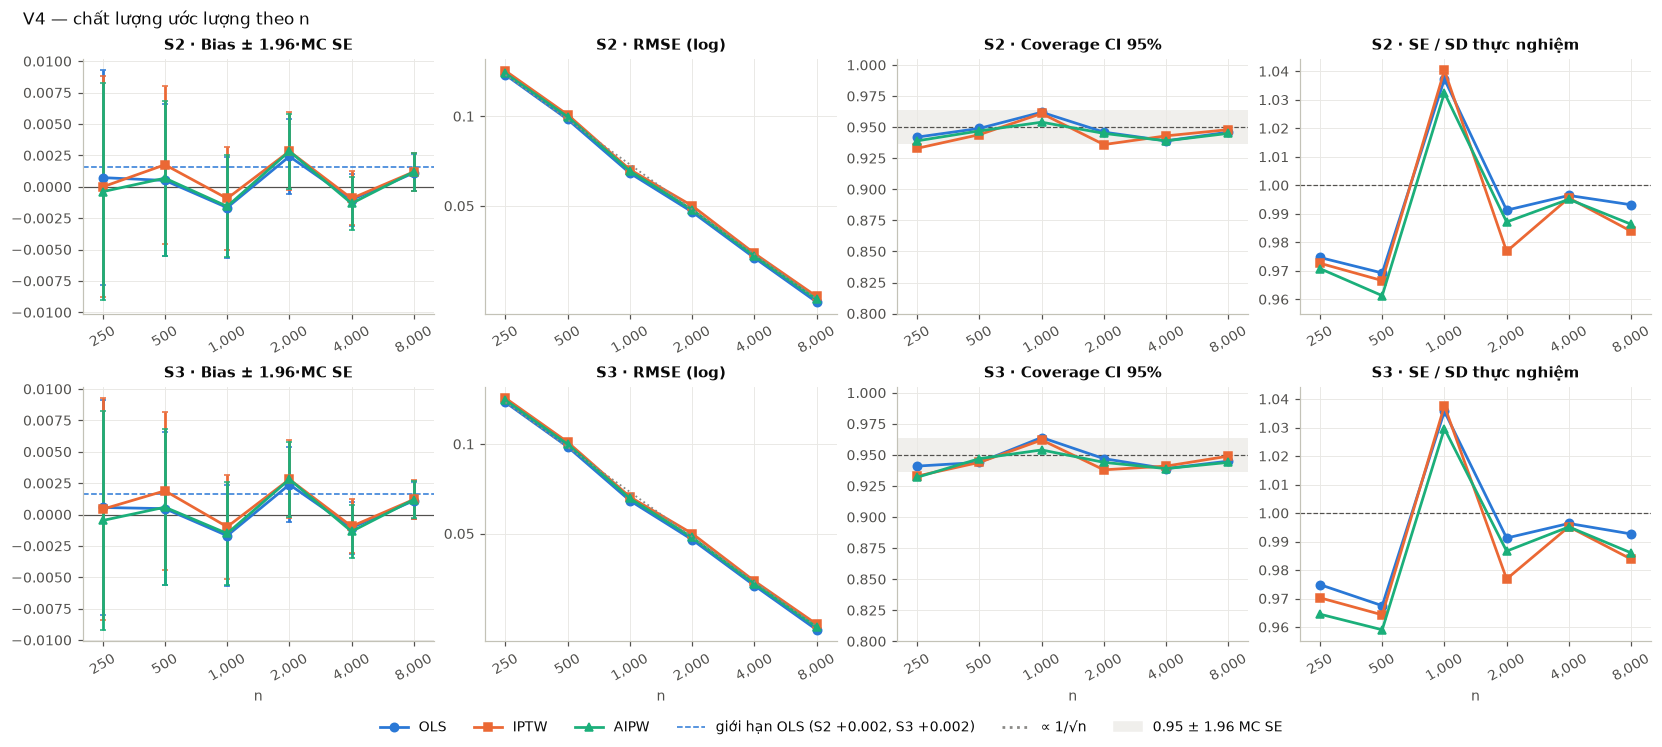

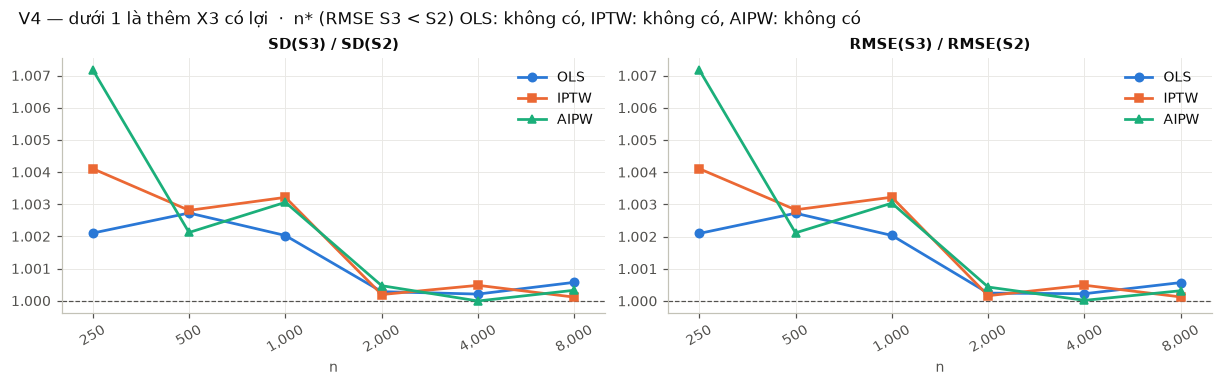

In [27]:
raw_V4, diag_V4 = run_mc(simulate_V4, "V4")
summary_V4 = report("V4", raw_V4, diag_V4, LIMIT_V4)

**Nhận xét V4.**
- **Kỳ vọng:** không chệch; SD gần như không đổi, chi phí thấy rõ hơn ở n nhỏ.
- **Kết quả:** S2 và S3 gần như trùng nhau ở mọi chỉ số. SD(S3)/SD(S2) cao nhất là 1.007 (AIPW, n = 250); OLS 1.002–1.003 ở n ≤ 1000; từ n = 2000 cả ba còn ≤ 1.001. ESS/n ở n = 250 giảm từ 0.860 xuống 0.855. n* "không có" nghĩa là S3 không bao giờ thắng, nhưng phần thua chỉ ở chữ số thứ ba.
- **Giải thích:** một biến thừa chỉ tốn một bậc tự do. Với OLS, mức tăng SD xấp xỉ 1/(2n) = 0.002 ở n = 250, cùng bậc với kết quả. Ở đây chỉ có một biến nhiễu trên n ≥ 250; kết luận này không tự động mở rộng cho nhiều biến nhiễu ở mẫu nhỏ.

### Cơ chế chung của V2, V3, V4

Ở cả ba kịch bản bias bằng 0, nên chỉ còn SD. Theo FWL, $\mathrm{SD}\cdot\sqrt n \approx \sigma_{\text{res}} / \mathrm{SD}(\tilde A)$:

- **Trái:** σ_res. Đưa X3 vào chỉ giảm σ_res khi X3 thực sự giải thích Y (**V2**).
- **Giữa:** SD(Ã), phần của A không đoán được từ design. Đưa X3 vào chỉ giảm SD(Ã) khi X3 thực sự giải thích A (**V3**).
- **Phải:** tỉ số của hai đại lượng trên là SD·√n dự đoán; chấm đen là SD thực nghiệm từ Monte Carlo ở n lớn nhất nhân √n.

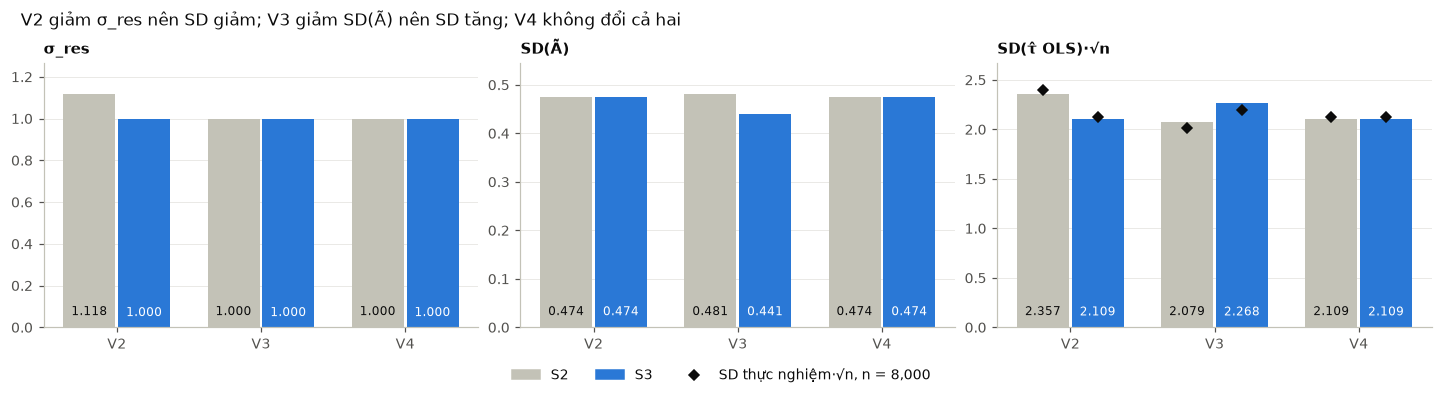

,SD(S3)/SD(S2) theo FWL,"SD(S3)/SD(S2) MC, n = 8,000"
V2,0.895,0.886
V3,1.091,1.089
V4,1.000,1.001


In [28]:
MECH = ("V2", "V3", "V4")
n_max = max(N_VALUES)
xs = np.arange(len(MECH))
bw = .38
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), layout="constrained")
for ax, col, title in zip(axes, ("σ_res", "SD(Ã)", "SD·√n"), ("σ_res", "SD(Ã)", "SD(τ̂ OLS)·√n")):
    for k, (analysis, color, off) in enumerate((("S2", C_POP, -bw/2), ("S3", C_OLS, bw/2))):
        vals = [THEORY[s].loc[analysis, col] for s in MECH]
        ax.bar(xs + off, vals, bw - .02, color=color, label=analysis)
        for x, v in zip(xs + off, vals):
            ax.text(x, .04*max(vals), f"{v:.3f}", ha="center", va="bottom",
                    color="white" if analysis == "S3" else INK, fontsize=8)
    ax.set_xticks(xs, MECH)
    ax.grid(axis="x", visible=False)
    ax.set_axisbelow(True)
    ax.set_title(title, loc="left")
    ax.set_ylim(bottom=0, top=ax.get_ylim()[1]*1.08)
mc = {(s, a): RESULTS[s][0].query("method == 'OLS' and analysis == @a and n == @n_max").emp_sd.iloc[0]*np.sqrt(n_max)
      for s in MECH for a in ("S2", "S3")}
for i, s in enumerate(MECH):
    for analysis, off in (("S2", -bw/2), ("S3", bw/2)):
        axes[2].plot(i + off, mc[s, analysis], marker="D", color=INK, ls="", markersize=5)
handles = [Patch(color=C_POP, label="S2"), Patch(color=C_OLS, label="S3"),
           Line2D([], [], marker="D", color=INK, ls="", markersize=5, label=f"SD thực nghiệm·√n, n = {n_max:,}")]
fig.legend(handles=handles, loc="outside lower center", ncol=3)
fig.suptitle("V2 giảm σ_res nên SD giảm; V3 giảm SD(Ã) nên SD tăng; V4 không đổi cả hai", x=0.01, ha="left")
fig.savefig(FIG_DIR / "V2_V3_V4_mechanism.png", bbox_inches="tight")
plt.show()
ratio_pred = pd.Series({s: THEORY[s].loc["S3", "SD·√n"]/THEORY[s].loc["S2", "SD·√n"] for s in MECH})
ratio_mc = pd.Series({s: mc[s, "S3"]/mc[s, "S2"] for s in MECH})
display(pd.DataFrame({"SD(S3)/SD(S2) theo FWL": ratio_pred, f"SD(S3)/SD(S2) MC, n = {n_max:,}": ratio_mc}).round(3))

## V5 — Confounder tương quan với X1

$$
\boldsymbol{X_3 = \rho X_1 + \sqrt{1-\rho^2}\,Z,\quad \rho = 0.7,\ Z \sim N(0,1)},\qquad
\operatorname{logit} e(X) = \gamma_0 + 0.5X_1 + 0.5X_2 + 0.5X_3,\qquad
\mu_0(X) = 0.5X_1 + 0.5X_2 + 0.5X_3
$$

Cùng γ3, β3 như **V1**, Var[X3] vẫn bằng 1, chỉ khác X3 tương quan với X1. Viết lại theo Z:

$$
\operatorname{logit} e(X) = \gamma_0 + 0.85X_1 + 0.5X_2 + 0.357Z,\qquad
\mu_0(X) = 0.85X_1 + 0.5X_2 + 0.357Z
$$

Với **S2**, phần X3 mà X1 đã "gánh" được hệ số 0.85 thay vì 0.5 hấp thụ; chỉ còn Z bị bỏ sót, hệ số 0.357 thay vì 0.5.

**Câu hỏi:** bỏ sót khi X3 tương quan với biến đã có thì sao; đưa vào thì cộng tuyến có hại không?
**Kỳ vọng (pilot):** S2 có bias OLS ≈ **+0.124**, khoảng một nửa **V1** (khớp 0.357²/0.5² ≈ 0.51). S3 không chệch. Naive chệch nhiều hơn **V1** (≈ 0.90).

In [29]:
RHO_V5 = 0.7


def dgp_V5(n, rng, rho=RHO_V5):
    x1 = rng.normal(size=n)
    x2 = rng.normal(size=n)
    x3 = rho*x1 + np.sqrt(1 - rho**2)*rng.normal(size=n)   # KHÁC V1: X3 tương quan với X1
    lin = 0.5*x1 + 0.5*x2 + 0.5*x3
    mu0 = 0.5*x1 + 0.5*x2 + 0.5*x3
    tau = np.full(n, TAU)
    return {"X1": x1, "X2": x2, "X3": x3}, lin, mu0, tau


GAMMA0_V5 = gamma0_for(dgp_V5, target=0.5)


def simulate_V5(n, seed):
    return simulate(dgp_V5, GAMMA0_V5, n, seed)

In [30]:
show_vs_base("V5", {**FORMULA_V1, "X3": "0.7·X1 + √0.51·Z"}, dgp_V5, GAMMA0_V5,
             base="V1", base_formulas=FORMULA_V1, base_dgp=dgp_V1, base_gamma0=GAMMA0_V1)
X_ref, *_ = reference_sample(dgp_V5)
assert abs(np.corrcoef(X_ref["X1"], X_ref["X3"])[0, 1] - RHO_V5) < .01
print("Kiểm tra V5: Corr(X1, X3) ≈ 0.7: PASS")

**V5 so với V1** (◆ = khác, = giống)

,V1,V5,khác
X3,"N(0,1)",0.7·X1 + √0.51·Z,◆
logit e(X),γ0 + 0.5·X1 + 0.5·X2 + 0.5·X3,γ0 + 0.5·X1 + 0.5·X2 + 0.5·X3,=
μ0(X),0.5·X1 + 0.5·X2 + 0.5·X3,0.5·X1 + 0.5·X2 + 0.5·X3,=
τ(X),2,2,=
P(A=1) mục tiêu,0.5,0.5,=
γ0,-0.0028,-0.0029,◆
P(A=1) trên mẫu tham chiếu,0.5000,0.5000,=
Var[X3],0.996,0.995,◆
"Corr(X1, X3)",-0.001,+0.700,◆
ESS/n kỳ vọng (e thật),0.81,0.73,◆


Kiểm tra V5: τ = 2, P(A=1) ≈ 0.5, Var[X3] ≈ 1: PASS
Kiểm tra V5: Corr(X1, X3) ≈ 0.7: PASS


In [31]:
LIMIT_V5 = large_sample_check(simulate_V5, dgp_V5, GAMMA0_V5, pilot={("S2", "Naive"): .90, ("S2", "OLS"): .124, ("S3", "OLS"): 0.})
show_fwl("V5", dgp_V5, GAMMA0_V5, LIMIT_V5)

**Một mẫu n = 2,000,000** — P(A=1) = 0.499

ước lượng    bias      SE  bias lý thuyết    lệch
analysis method                                                   
S2       Naive      2.8933  0.8933  0.0019          0.8937 -0.0004
         OLS        2.1229  0.1229  0.0016          0.1232 -0.0003
         IPTW       2.1239  0.1239  0.0019          0.1247 -0.0008
         AIPW       2.1232  0.1232  0.0017          0.1237 -0.0004
S3       OLS        1.9994 -0.0006  0.0016          0.0000 -0.0006
         IPTW       1.9996 -0.0004  0.0019          0.0000 -0.0004
         AIPW       1.9990 -0.0010  0.0016          0.0000 -0.0010

,ESS/n,e min,e max,trọng số lớn nhất,max |SMD| trước,max |SMD| sau IPTW,SMD X3 sau IPTW
S2,0.776,0.009,0.991,39.417,0.737,0.001,0.265
S3,0.735,0.006,0.994,67.122,0.737,0.001,0.001


Lệch lớn nhất so với lý thuyết: 0.0010
Pilot README, Naive S2: +0.900; mẫu lớn +0.8933
Pilot README, OLS S2: +0.124; mẫu lớn +0.1229
Pilot README, OLS S3: +0.000; mẫu lớn -0.0006


**V5: cơ chế OLS theo FWL** (mẫu tham chiếu; SD ở n = 2000 = SD·√n / √2000)

,SD(Ã),σ_res,SD·√n,bias FWL,SD ở n = 2000,bias mẫu lớn
S2,0.4580,1.0601,2.3145,0.1232,0.0518,0.1229
S3,0.4522,1.0000,2.2113,0.0000,0.0494,-0.0006


### V1 so với V5: X1 gánh một phần X3

- **Hai hình đầu:** balance của **S2** trên một mẫu n = 2000. Sau IPTW, X1 và X2 đều cân bằng. Riêng X3, cân bằng theo X1 cũng kéo theo một phần X3 (phần tương quan), nên |SMD| của X3 ở **V5** thấp hơn **V1**, nhưng chưa về 0.
- **Hình phải:** bias OLS của S2 theo công thức FWL khi ρ thay đổi, giữ nguyên các hệ số khác (γ0 hiệu chỉnh lại ở từng ρ). Đường chấm là xấp xỉ $\text{bias}_{\rho=0}\,(1-\rho^2)$, tức bias tỉ lệ với bình phương hệ số của phần Z bị bỏ sót. Các ρ khác 0 và 0.7 chỉ để minh họa, không chạy Monte Carlo.

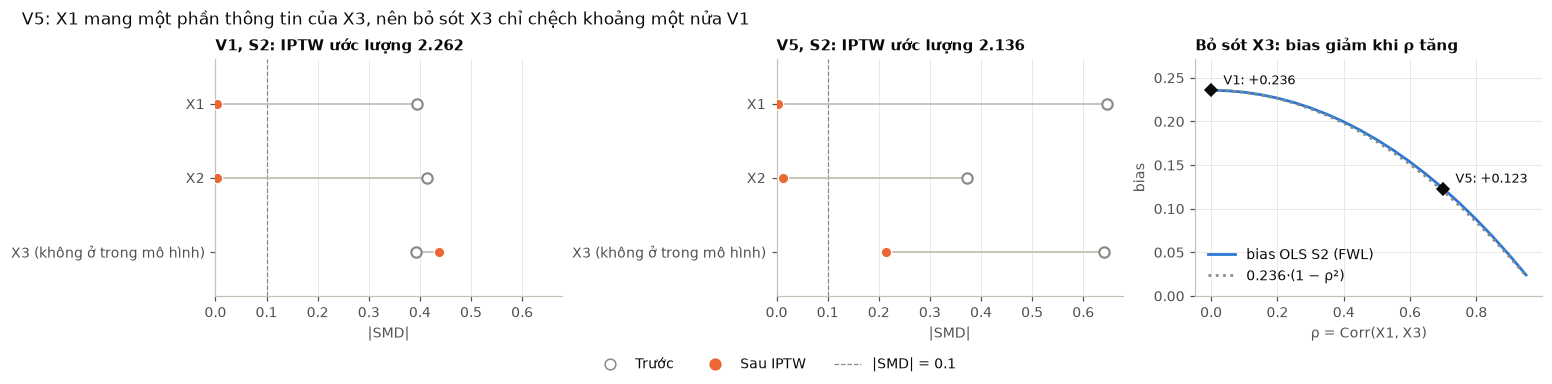

V1                         V5               
         |SMD| trước |SMD| sau IPTW |SMD| trước |SMD| sau IPTW
variable                                                      
X1             0.395          0.003       0.646          0.003
X2             0.414          0.003       0.373          0.012
X3             0.393          0.438       0.640          0.215

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.4), layout="constrained")
rows = {}
for ax, (name, simulate_fn) in zip(axes, (("V1", simulate_V1), ("V5", simulate_V5))):
    df_love, _ = simulate_fn(2000, SEED)
    cols = ANALYSES["S2"]
    estimates, e, *_ = estimate_all(df_love, make_design(df_love, cols))
    rows[name] = draw_love(ax, df_love, e, f"{name}, S2: IPTW ước lượng {estimates['IPTW'][0]:.3f}", cols)
axes[0].set_xlim(axes[1].get_xlim())

rhos = np.linspace(0, .95, 20)
bias_rho = []
for rho in rhos:
    dgp_rho = lambda n, rng, rho=rho: dgp_V5(n, rng, rho=rho)
    bias_rho.append(ols_theory(dgp_rho, gamma0_for(dgp_rho)).loc["S2", "bias FWL"])
ax = axes[2]
ax.plot(rhos, bias_rho, color=C_OLS, label="bias OLS S2 (FWL)")
ax.plot(rhos, bias_rho[0]*(1 - rhos**2), color=INK_3, ls=":", label=f"{bias_rho[0]:.3f}·(1 − ρ²)")
for rho, name, limit in ((0., "V1", LIMIT_V1), (RHO_V5, "V5", LIMIT_V5)):
    ax.plot(rho, limit["ols_bias"]["S2"], marker="D", color=INK, ls="", markersize=6)
    ax.annotate(f"{name}: {limit['ols_bias']['S2']:+.3f}", (rho, limit["ols_bias"]["S2"]), xytext=(8, 4),
                textcoords="offset points", color=INK, fontsize=8.5)
ax.set_xlabel("ρ = Corr(X1, X3)")
ax.set_ylabel("bias")
ax.set_ylim(0, 1.15*bias_rho[0])
ax.set_title("Bỏ sót X3: bias giảm khi ρ tăng", loc="left")
ax.legend(loc="lower left")
fig.legend(handles=LOVE_HANDLES, loc="outside lower center", ncol=3)
fig.suptitle("V5: X1 mang một phần thông tin của X3, nên bỏ sót X3 chỉ chệch khoảng một nửa V1", x=0.01, ha="left")
fig.savefig(FIG_DIR / "V1_vs_V5.png", bbox_inches="tight")
plt.show()
display(pd.concat(rows, axis=1).round(3))

V5: n=[250, 500, 1000, 2000, 4000, 8000], R=1000 — 88s


**V5, S2: bias, RMSE, coverage, SE/SD theo n** (R = 1000)

bias                 rmse               coverage               se_sd_ratio              
method    OLS   IPTW   AIPW    OLS   IPTW   AIPW      OLS   IPTW   AIPW         OLS   IPTW   AIPW
n                                                                                                
250     0.131  0.140  0.131  0.198  0.224  0.203    0.854  0.825  0.856       0.993  0.932  0.979
500     0.123  0.127  0.123  0.159  0.175  0.163    0.802  0.778  0.788       1.025  0.972  1.008
1000    0.127  0.129  0.126  0.148  0.155  0.149    0.587  0.623  0.607       0.962  0.957  0.970
2000    0.125  0.127  0.126  0.135  0.140  0.137    0.324  0.417  0.359       1.010  0.989  1.011
4000    0.123  0.125  0.124  0.129  0.131  0.130    0.087  0.155  0.094       0.982  1.032  1.000
8000    0.126  0.126  0.126  0.128  0.130  0.129    0.003  0.012  0.005       0.971  1.016  0.990

**V5, S3: bias, RMSE, coverage, SE/SD theo n** (R = 1000)

bias                 rmse               coverage               se_sd_ratio              
method    OLS   IPTW   AIPW    OLS   IPTW   AIPW      OLS   IPTW   AIPW         OLS   IPTW   AIPW
n                                                                                                
250     0.005  0.018  0.006  0.141  0.182  0.153    0.950  0.916  0.940       0.999  0.911  0.962
500    -0.003  0.001 -0.003  0.098  0.130  0.106    0.954  0.933  0.943       1.011  0.913  0.982
1000    0.003  0.003  0.002  0.072  0.092  0.076    0.947  0.934  0.947       0.974  0.940  0.975
2000    0.001  0.000  0.001  0.049  0.061  0.052    0.959  0.952  0.954       1.016  1.003  1.009
4000   -0.001 -0.000 -0.000  0.036  0.042  0.037    0.948  0.958  0.958       0.984  1.025  0.993
8000    0.002  0.001  0.002  0.026  0.031  0.027    0.933  0.951  0.945       0.961  1.003  0.969

**Chẩn đoán trung bình qua rep** (`x3_smd_after` chỉ mô phỏng mới đo được)

,,ess_ratio,e_min,e_max,max_weight,max_abs_smd_before,max_abs_smd_after,x3_smd_after,ps_failed_reps
analysis,n,,,,,,,,
S2,250,0.763,0.066,0.934,10.507,0.746,0.068,0.277,0
S3,250,0.719,0.051,0.949,12.250,0.791,0.086,0.011,0
S2,500,0.768,0.056,0.945,12.084,0.739,0.048,0.271,0
S3,500,0.725,0.043,0.959,14.286,0.770,0.063,0.003,0
S2,1000,0.772,0.045,0.955,13.811,0.738,0.034,0.268,0
S3,1000,0.729,0.034,0.966,16.623,0.761,0.044,0.001,0
S2,2000,0.772,0.037,0.962,16.180,0.740,0.025,0.267,0
S3,2000,0.727,0.028,0.972,19.777,0.756,0.033,-0.001,0
S2,4000,0.773,0.031,0.969,18.773,0.739,0.017,0.265,0


**SD(S3) / SD(S2) theo n**

method,OLS,IPTW,AIPW
n,,,
250,0.953,1.037,0.989
500,0.970,1.086,0.997
1000,0.945,1.053,0.964
2000,0.950,1.025,0.974
4000,0.953,1.043,0.978
8000,0.966,1.052,0.992


S2: bias OLS (MC) nằm trong 3 SE quanh giới hạn +0.1229 ở 6/6 giá trị n
S2: SD OLS ở n = 8,000: MC 0.0266, FWL 0.0259
S3: bias OLS (MC) nằm trong 3 SE quanh giới hạn -0.0006 ở 6/6 giá trị n
S3: SD OLS ở n = 8,000: MC 0.0257, FWL 0.0247


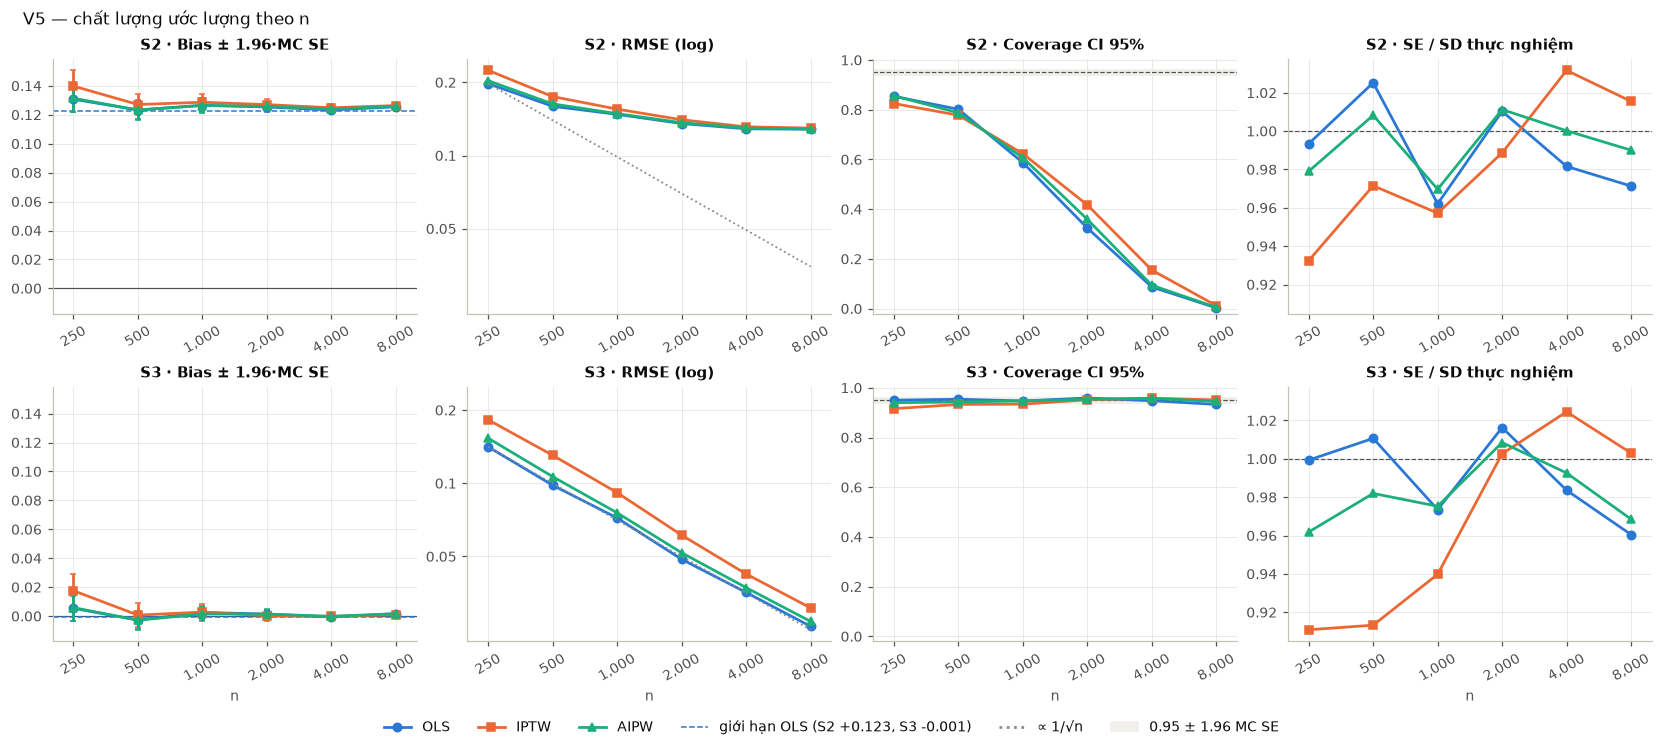

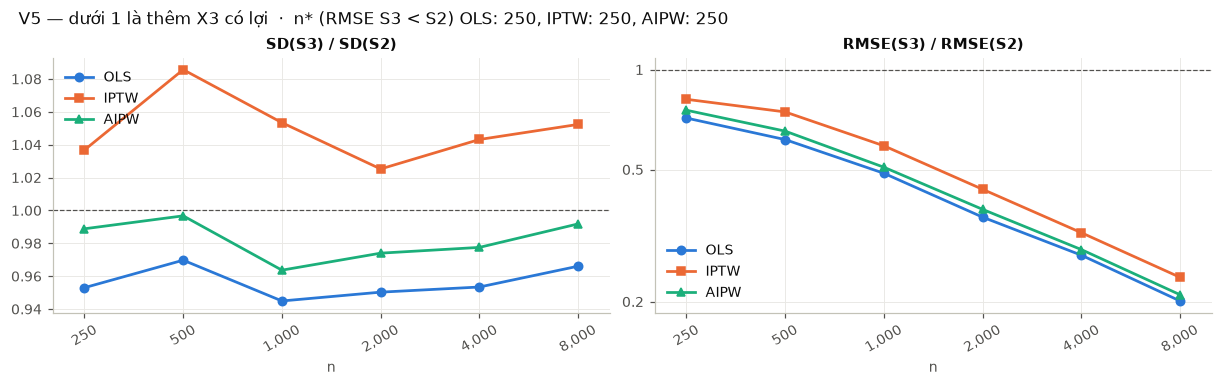

In [33]:
raw_V5, diag_V5 = run_mc(simulate_V5, "V5")
summary_V5 = report("V5", raw_V5, diag_V5, LIMIT_V5)

**Nhận xét V5.**
- **Kỳ vọng:** S2 chệch khoảng +0.124, một nửa **V1**; S3 không chệch.
- **Kết quả:** S2 có bias OLS +0.123 đến +0.131, khớp giới hạn +0.123 và FWL +0.123; tỉ số so với **V1** là 0.52, gần 1 − ρ² = 0.51. Bias nhỏ hơn nên coverage giảm chậm hơn **V1**, nhưng vẫn về gần 0: OLS 0.854 ở n = 250, **0.003** ở n = 8000. S3 có bias OLS ≤ 0.005, IPTW +0.018 ở n = 250 rồi về ≤ 0.003. S3 thắng về RMSE ở mọi n và mọi estimator (n = 250, OLS: 0.141 so với 0.198). Coverage của OLS S3 ở n = 8000 là 0.933, thấp khoảng 2.4 MC SE, nhưng các n khác nằm trong 0.947–0.959 nên có thể chỉ là dao động Monte Carlo.
- **Giải thích:** X1 hấp thụ phần X3 tương quan với nó (hệ số 0.85), nên chỉ còn phần Z với hệ số 0.357 bị bỏ sót, cả trong PS lẫn outcome. Bias tỉ lệ với tích hai hệ số đó, nên giảm theo 0.357²/0.5² ≈ 0.51. SMD của X3 sau IPTW giảm còn 0.27 (**V1**: 0.49) nhưng vẫn trên ngưỡng 0.1, còn max |SMD| trên biến quan sát giảm từ 0.068 (n = 250) xuống 0.012 (n = 8000): balance vẫn không báo động. Naive chệch nhiều hơn (+0.893 so với +0.643) vì confounding tổng thể mạnh hơn. **Cộng tuyến gần như không phải vấn đề:** SD(Ã) chỉ giảm từ 0.458 xuống 0.452 khi thêm X3, nên SD của OLS vẫn giảm (0.95–0.97 lần), AIPW 0.96–1.00 lần. Riêng IPTW tăng 1.03–1.09 lần vì ESS/n giảm từ 0.77 xuống 0.73, nhưng phần giảm bias lớn hơn nhiều so với phần tăng này.

## Tổng hợp

Gộp mọi kịch bản: bias và coverage theo n, giới hạn trên mẫu lớn, tỉ số SD của S3 so với S2, n* (n nhỏ nhất mà từ đó trở đi S3 có RMSE thấp hơn S2; "không có" nghĩa là không có n nào như vậy trên lưới).
Kết quả lưu ở `results/part_B_summary.csv`, `results/part_B_diagnostic_summary.csv`, `results/part_B_metadata.json`, `results/part_B_conclusions.md`.

In [34]:
ORDER = list(RESULTS)
summary_B = pd.concat([RESULTS[s][0] for s in ORDER], ignore_index=True)
diag_B = pd.concat([RESULTS[s][1] for s in ORDER], ignore_index=True)
summary_B.to_csv(RESULT_DIR / "part_B_summary.csv", index=False)
diag_B.to_csv(RESULT_DIR / "part_B_diagnostic_summary.csv", index=False)

# Kiểm tra CSV sau khi đọc lại: khóa duy nhất, đủ method/rep, đếm failure đúng.
raw_all = pd.concat([pd.read_csv(RESULT_DIR / f"{s}.csv") for s in ORDER], ignore_index=True)
diag_all = pd.concat([pd.read_csv(RESULT_DIR / f"{s}_diagnostics.csv") for s in ORDER], ignore_index=True)
assert not raw_all.duplicated(["scenario", "analysis", "n", "rep", "method"]).any()
assert not diag_all.duplicated(["scenario", "analysis", "n", "rep"]).any()
assert raw_all.groupby(["scenario", "analysis", "n", "rep"]).size().eq(len(METHODS)).all()
assert summary_B.R.eq(R).all()
assert (summary_B.valid_reps + summary_B.failed_reps).eq(R).all()
print(f"Kiểm tra CSV: {len(raw_all):,} dòng ước lượng, {len(diag_all):,} dòng chẩn đoán, "
      f"{int(summary_B.failed_reps.sum())} lần fit lỗi: PASS")

for value, fmt in (("bias", "{:+.3f}"), ("coverage", "{:.3f}")):
    wide = (summary_B[summary_B.method.isin(ADJUSTED)]
            .pivot_table(index=["scenario", "analysis", "method"], columns="n", values=value, sort=False))
    display(Markdown(f"**{value} theo n**"))
    display(wide.map(fmt.format))

n_max = max(N_VALUES)
overview = pd.DataFrame({
    (s, a): {"giới hạn Naive": RESULTS[s][2]["table"].loc[(next(iter(RESULTS[s][2]["ols_bias"])), "Naive"), "bias"],
             **{f"giới hạn {m}": RESULTS[s][2]["table"].loc[(a, m), "bias"] for m in ADJUSTED},
             "SD OLS·√n (FWL)": THEORY[s].loc[a, "SD·√n"],
             "ESS/n (n lớn nhất)": RESULTS[s][1].query("analysis == @a and n == @n_max").ess_ratio.iloc[0],
             "SMD X3 sau IPTW": RESULTS[s][1].query("analysis == @a and n == @n_max").x3_smd_after.iloc[0],
             "coverage OLS (n lớn nhất)": RESULTS[s][0].query("analysis == @a and n == @n_max and method == 'OLS'").coverage.iloc[0]}
    for s in ORDER for a in RESULTS[s][2]["ols_bias"]}).T
display(Markdown("**Giới hạn bias trên mẫu lớn, ESS, balance của X3, coverage**"))
display(overview.round(3).astype(object).where(overview.notna(), "không có X3"))

ratio = pd.DataFrame({
    s: {**{f"SD S3/S2 {m}, n = {n:,}": s3_over_s2(RESULTS[s][0], "emp_sd").loc[n, m]
           for n in (N_VALUES[0], n_max) for m in ADJUSTED},
        **{f"n* {m}": n_star(RESULTS[s][0], m) or "không có" for m in ADJUSTED}}
    for s in ORDER if s != "V0"}).T
display(Markdown("**S3 so với S2**"))
fmts = {c: (lambda v: v if v == "không có" else f"{int(v):,}") if c.startswith("n*") else "{:.3f}".format for c in ratio.columns}
display(ratio.apply(lambda col: col.map(fmts[col.name])))

Kiểm tra CSV: 264,000 dòng ước lượng, 66,000 dòng chẩn đoán, 0 lần fit lỗi: PASS


**bias theo n**

n                           250     500     1000    2000    4000    8000
scenario analysis method                                                
V0       S2       OLS     -0.008  +0.000  -0.001  +0.001  +0.000  -0.001
                  IPTW    -0.006  -0.000  -0.000  +0.001  +0.000  -0.001
                  AIPW    -0.009  -0.001  -0.001  +0.001  +0.000  -0.001
V1       S2       OLS     +0.240  +0.236  +0.240  +0.239  +0.236  +0.237
                  IPTW    +0.242  +0.237  +0.241  +0.240  +0.237  +0.238
                  AIPW    +0.240  +0.236  +0.240  +0.239  +0.236  +0.237
         S3       OLS     +0.002  -0.001  +0.002  +0.002  +0.001  +0.000
                  IPTW    +0.004  -0.000  +0.002  +0.001  +0.001  -0.000
                  AIPW    +0.001  -0.001  +0.001  +0.002  +0.001  -0.000
V2       S2       OLS     +0.002  -0.002  +0.003  +0.002  +0.001  -0.000
                  IPTW    +0.005  -0.001  +0.005  +0.001  +0.002  +0.000
                  AIPW    +0.003  -0.002  +0.004  +0.002  +0.002  -0.000
         S3       OLS     +0.003  +0.001  +0.003  +0.001  +0.001  -0.000
                  IPTW    +0.005  +0.002  +0.004  +0.000  +0.001  +0.001
                  AIPW    +0.003  +0.001  +0.003  +0.001  +0.001  +0.000
V3       S2       OLS     +0.007  +0.001  +0.002  +0.002  -0.002  +0.001
                  IPTW    +0.010  +0.003  +0.003  +0.002  -0.001  +0.002
                  AIPW    +0.007  +0.001  +0.002  +0.001  -0.002  +0.001
         S3       OLS     +0.009  +0.001  +0.003  +0.002  -0.002  +0.001
                  IPTW    +0.020  +0.003  +0.003  +0.004  -0.002  +0.001
                  AIPW    +0.011  -0.000  +0.003  +0.003  -0.002  +0.002
V4       S2       OLS     +0.001  +0.001  -0.002  +0.002  -0.001  +0.001
                  IPTW    -0.000  +0.002  -0.001  +0.003  -0.001  +0.001
                  AIPW    -0.000  +0.001  -0.002  +0.003  -0.001  +0.001
         S3       OLS     +0.001  +0.000  -0.002  +0.002  -0.001  +0.001
                  IPTW    +0.000  +0.002  -0.001  +0.003  -0.001  +0.001
                  AIPW    -0.000  +0.001  -0.002  +0.003  -0.001  +0.001
V5       S2       OLS     +0.131  +0.123  +0.127  +0.125  +0.123  +0.126
                  IPTW    +0.140  +0.127  +0.129  +0.127  +0.125  +0.126
                  AIPW    +0.131  +0.123  +0.126  +0.126  +0.124  +0.126
         S3       OLS     +0.005  -0.003  +0.003  +0.001  -0.001  +0.002
                  IPTW    +0.018  +0.001  +0.003  +0.000  -0.000  +0.001
                  AIPW    +0.006  -0.003  +0.002  +0.001  -0.000  +0.002

**coverage theo n**

n                          250    500    1000   2000   4000   8000
scenario analysis method                                          
V0       S2       OLS     0.954  0.952  0.951  0.958  0.955  0.946
                  IPTW    0.955  0.950  0.953  0.950  0.953  0.951
                  AIPW    0.958  0.948  0.953  0.950  0.948  0.953
V1       S2       OLS     0.620  0.382  0.096  0.006  0.000  0.000
                  IPTW    0.613  0.403  0.116  0.010  0.000  0.000
                  AIPW    0.615  0.390  0.112  0.007  0.000  0.000
         S3       OLS     0.956  0.950  0.953  0.944  0.953  0.944
                  IPTW    0.949  0.950  0.947  0.944  0.951  0.946
                  AIPW    0.952  0.940  0.944  0.947  0.951  0.940
V2       S2       OLS     0.945  0.948  0.954  0.945  0.948  0.950
                  IPTW    0.944  0.948  0.943  0.950  0.945  0.955
                  AIPW    0.947  0.948  0.943  0.949  0.942  0.952
         S3       OLS     0.942  0.956  0.946  0.953  0.950  0.949
                  IPTW    0.944  0.953  0.930  0.957  0.942  0.948
                  AIPW    0.949  0.951  0.936  0.959  0.942  0.943
V3       S2       OLS     0.942  0.952  0.952  0.957  0.953  0.950
                  IPTW    0.941  0.950  0.947  0.956  0.958  0.953
                  AIPW    0.941  0.952  0.953  0.955  0.955  0.957
         S3       OLS     0.938  0.943  0.944  0.953  0.951  0.954
                  IPTW    0.920  0.925  0.935  0.948  0.950  0.945
                  AIPW    0.934  0.933  0.941  0.951  0.949  0.952
V4       S2       OLS     0.942  0.949  0.962  0.946  0.939  0.946
                  IPTW    0.933  0.944  0.961  0.936  0.943  0.948
                  AIPW    0.939  0.947  0.954  0.945  0.939  0.945
         S3       OLS     0.941  0.944  0.964  0.947  0.939  0.945
                  IPTW    0.933  0.944  0.962  0.938  0.941  0.949
                  AIPW    0.932  0.947  0.954  0.944  0.939  0.944
V5       S2       OLS     0.854  0.802  0.587  0.324  0.087  0.003
                  IPTW    0.825  0.778  0.623  0.417  0.155  0.012
                  AIPW    0.856  0.788  0.607  0.359  0.094  0.005
         S3       OLS     0.950  0.954  0.947  0.959  0.948  0.933
                  IPTW    0.916  0.933  0.934  0.952  0.958  0.951
                  AIPW    0.940  0.943  0.947  0.954  0.958  0.945

**Giới hạn bias trên mẫu lớn, ESS, balance của X3, coverage**

giới hạn Naive giới hạn OLS giới hạn IPTW giới hạn AIPW SD OLS·√n (FWL) ESS/n (n lớn nhất) SMD X3 sau IPTW coverage OLS (n lớn nhất)
V0 S2          0.449          0.0          -0.0           0.0           2.109              0.875     không có X3                     0.946
V1 S2          0.643        0.236         0.237         0.236           2.334              0.888           0.486                       0.0
   S3          0.643          0.0         0.001         0.001           2.155              0.814            -0.0                     0.944
V2 S2          0.448        0.001         0.001         0.001           2.357              0.875          -0.001                      0.95
   S3          0.448        0.002         0.002         0.002           2.109              0.875            -0.0                     0.949
V3 S2          0.384       -0.002        -0.001        -0.002           2.079              0.913           0.904                      0.95
   S3          0.384       -0.002        -0.002        -0.002           2.268              0.643           0.001                     0.954
V4 S2          0.449        0.002         0.002         0.002           2.109              0.875            -0.0                     0.946
   S3          0.449        0.002         0.002         0.002           2.109              0.875            -0.0                     0.945
V5 S2          0.893        0.123         0.124         0.123           2.315              0.774           0.265                     0.003
   S3          0.893       -0.001          -0.0        -0.001           2.211              0.731          -0.001                     0.933

**S3 so với S2**

,"SD S3/S2 OLS, n = 250","SD S3/S2 IPTW, n = 250","SD S3/S2 AIPW, n = 250","SD S3/S2 OLS, n = 8,000","SD S3/S2 IPTW, n = 8,000","SD S3/S2 AIPW, n = 8,000",n* OLS,n* IPTW,n* AIPW
V1,0.935,1.016,0.951,0.920,0.976,0.937,250,250,250
V2,0.884,0.902,0.890,0.886,0.895,0.891,250,250,250
V3,1.100,1.286,1.191,1.089,1.273,1.162,không có,không có,không có
V4,1.002,1.004,1.007,1.001,1.000,1.000,không có,không có,không có
V5,0.953,1.037,0.989,0.966,1.052,0.992,250,250,250


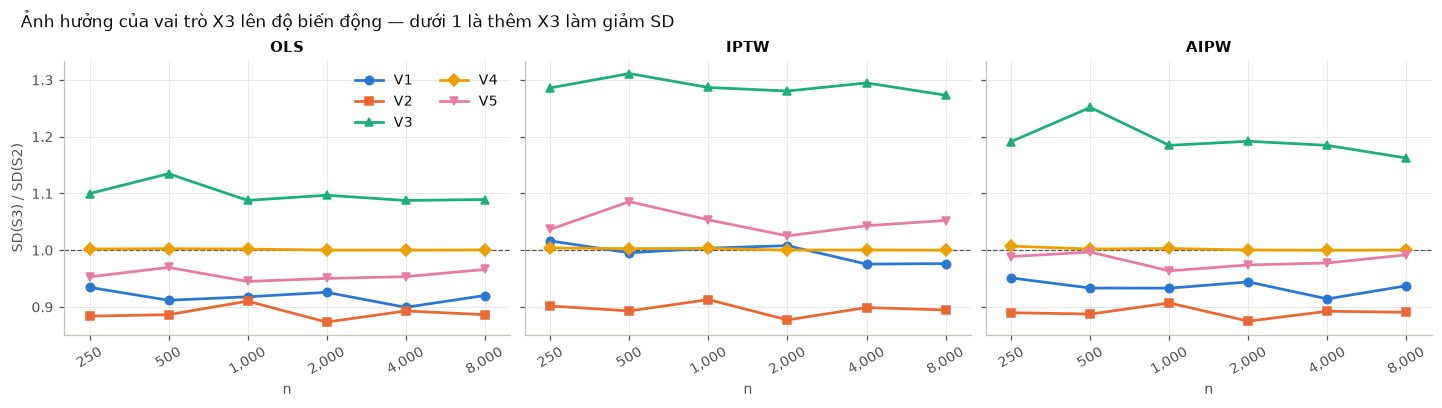

Đã lưu part_B_summary.csv, part_B_diagnostic_summary.csv, part_B_metadata.json, part_B_conclusions.md, X3_sd_ratio.png


In [35]:
markers = "os^Dv"
fig, axes = plt.subplots(1, len(ADJUSTED), figsize=(13, 3.6), sharey=True, layout="constrained")
for ax, m in zip(axes, ADJUSTED):
    ax.axhline(1, color=INK_2, lw=.8, ls="--")
    for i, s in enumerate(s for s in ORDER if s != "V0"):
        r = s3_over_s2(RESULTS[s][0], "emp_sd")
        ax.plot(r.index, r[m], color=CATEGORICAL[i], marker=markers[i], label=s)
    style_n_axis(ax, N_VALUES)
    ax.set_title(m)
    ax.set_xlabel("n")
axes[0].set_ylabel("SD(S3) / SD(S2)")
axes[0].legend(loc="upper right", ncol=2)
fig.suptitle("Ảnh hưởng của vai trò X3 lên độ biến động — dưới 1 là thêm X3 làm giảm SD", x=0.01, ha="left")
fig.savefig(RESULT_DIR / "X3_sd_ratio.png", bbox_inches="tight")
plt.show()

metadata = {"part": "B", "R": int(summary_B.R.max()), "seed": SEED, "n": list(N_VALUES),
            "tau": TAU, "sigma": SIGMA, "n_ref": N_REF, "n_large": N_LARGE, "calibration_seed": 12345,
            "ps": "unpenalized estimated logistic, no clipping",
            "constants": {"beta": [0., .5, .5], "gamma": [.5, .5],
                          "V1": {"gamma3": .5, "beta3": .5}, "V2": {"gamma3": 0., "beta3": .5},
                          "V3": {"gamma3": 1., "beta3": 0.}, "V4": {"gamma3": 0., "beta3": 0.},
                          "V5": {"gamma3": .5, "beta3": .5, "rho": RHO_V5}},
            "versions": {"numpy": np.__version__, "pandas": pd.__version__,
                         "scipy": scipy.__version__, "statsmodels": statsmodels.__version__},
            "gamma0": {s: float(globals()[f"GAMMA0_{s}"]) for s in ORDER},
            "large_sample_bias": {s: {f"{a}/{m}": round(float(v), 5)
                                      for (a, m), v in RESULTS[s][2]["table"]["bias"].items()} for s in ORDER}}
(RESULT_DIR / "part_B_metadata.json").write_text(json.dumps(metadata, indent=2, ensure_ascii=False),
                                                 encoding="utf-8")


def conclude_added(n=2000 if 2000 in N_VALUES else max(N_VALUES)):
    # Kết luận sinh trực tiếp từ bảng kết quả, ở cùng một n.
    ols = summary_B[(summary_B.n == n) & (summary_B.method == "OLS")].set_index(["scenario", "analysis"])
    diag = diag_B[diag_B.n == n].set_index(["scenario", "analysis"])
    ratios = {s: ols.loc[(s, "S3"), "emp_sd"]/ols.loc[(s, "S2"), "emp_sd"] for s in ("V2", "V3", "V4")}
    lines = [f"Với R={summary_B.R.max()}, n={n}, bỏ X3 ở V1 có bias OLS {ols.loc[('V1', 'S2'), 'bias']:+.3f}; "
             f"thêm X3 có bias {ols.loc[('V1', 'S3'), 'bias']:+.3f}. "
             f"Max |SMD| trung bình sau IPTW trên biến S2 là {diag.loc[('V1', 'S2'), 'max_abs_smd_after']:.3f} "
             f"nhưng SMD X3 bị bỏ sót là {diag.loc[('V1', 'S2'), 'x3_smd_after']:.3f}. "
             "Balance tốt trên biến quan sát không chứng minh hết confounding.",
             "Tỉ lệ SD OLS S3/S2: " + "; ".join(f"{s}={v:.3f}" for s, v in ratios.items()) + ". "
             "Biến tiên lượng Y có lợi cho độ chính xác; biến chỉ tác động A làm tăng phương sai "
             "và giảm ESS; biến noise gần như không đổi.",
             f"V5 tương quan rho=0.7: bias S2 {ols.loc[('V5', 'S2'), 'bias']:+.3f}, "
             f"S3 {ols.loc[('V5', 'S3'), 'bias']:+.3f}. X1 chỉ mang một phần thông tin của X3.",
             "Số biến cần dựa trên vai trò trong DAG. Các kết luận này áp dụng cho DGP và estimator "
             "đang xét. V7 hậu điều trị là tùy chọn chưa chạy."]
    return "\n\n".join(lines)


(RESULT_DIR / "part_B_conclusions.md").write_text(conclude_added(), encoding="utf-8")
print("Đã lưu part_B_summary.csv, part_B_diagnostic_summary.csv, part_B_metadata.json, part_B_conclusions.md, X3_sd_ratio.png")

## Kết luận

Lưới n = 250 … 8000, R = 1000. Giới hạn bias lấy từ một mẫu n = 2·10⁶. SD S3/S2 và ESS/n lấy ở n = 8000. n* là n nhỏ nhất mà từ đó trở đi S3 có RMSE thấp hơn S2, xét trên OLS (IPTW và AIPW cho cùng kết quả).

| Kịch bản | Giới hạn bias OLS: S2 / S3 | Coverage OLS: S2 / S3 | SD S3/S2: OLS | IPTW | AIPW | ESS/n: S2 → S3 | n* |
|---|---|---|---|---|---|---|---|
| **V0** (mốc) | +0.000 / không có S3 | 0.946 / không có S3 | không có S3 | không có S3 | không có S3 | 0.875 (chỉ có S2) | không có S3 |
| **V1** (confounder) | **+0.236** / +0.000 | **0.000** / 0.944 | 0.920 | 0.976 | 0.937 | 0.888 → 0.814 | 250 |
| **V2** (chỉ Y) | +0.001 / +0.002 | 0.950 / 0.949 | **0.886** | **0.895** | **0.891** | 0.875 → 0.875 | 250 |
| **V3** (chỉ A) | −0.002 / −0.002 | 0.950 / 0.954 | **1.089** | **1.273** | **1.162** | 0.913 → **0.643** | không có |
| **V4** (noise) | +0.002 / +0.002 | 0.946 / 0.945 | 1.001 | 1.000 | 1.000 | 0.875 → 0.875 | không có |
| **V5** (confounder, ρ = 0.7) | **+0.123** / −0.001 | **0.003** / 0.933 | 0.966 | 1.052 | 0.992 | 0.774 → 0.731 | 250 |

1. **Bỏ sót confounder là lỗi đắt nhất và không tự khỏi.** Ở **V1** và **V5**, bias của S2 không giảm theo n và coverage về gần 0, ở cả OLS, IPTW lẫn AIPW. Không phương pháp nào trong ba cái sửa được khi biến không có trong dữ liệu.
2. **Balance tốt không chứng minh hết confounding.** Ở **V1**, max |SMD| trên biến quan sát chỉ còn 0.006–0.034 trong khi SMD của X3 khoảng 0.49. Ngược lại, ở **V3**, SMD của X3 khoảng 0.90 nhưng S2 không chệch. SMD của một biến chỉ có ý nghĩa khi biến đó liên quan tới Y.
3. **Biến tiên lượng Y nên đưa vào.** **V2** giảm SD khoảng 10% ở cả ba phương pháp mà không mất ESS và không có chi phí ở n nhỏ.
4. **Biến chỉ tác động lên A không nên đưa vào, nhất là với IPTW.** **V3** không có lợi gì về bias, trong khi SD tăng khoảng 9–14% (OLS), 16–25% (AIPW), 27–31% (IPTW). ESS/n giảm từ 0.91 xuống 0.64, và IPTW có coverage khoảng 0.92 ở n ≤ 500.
5. **Một biến thừa gần như miễn phí, cộng tuyến ρ = 0.7 cũng không phải lý do để bỏ biến.** **V4** tốn tối đa 0.7% SD ở n = 250. Ở **V5**, đưa X3 vào vẫn thắng về RMSE ở mọi n dù SD của IPTW tăng 3–9%.
6. **Hai kênh giải thích hết các khác biệt của OLS.** Theo FWL, X3 ảnh hưởng qua σ_res (giảm nếu X3 giải thích Y) và SD(Ã) (giảm nếu X3 giải thích A). Công thức dự đoán đúng cả bias (**V1** +0.236, **V5** +0.123) lẫn tỉ số SD (**V2** 0.895, **V3** 1.091) so với Monte Carlo. Vì vậy, chọn biến nên dựa trên vai trò trong DAG, không dựa trên số biến hay mức độ dự đoán A.

Các kết luận áp dụng cho DGP đang xét: τ hằng số, μ0 và PS tuyến tính đúng dạng theo tập biến đủ, một biến X3. Số 12% và 15% của pilot trong README lấy ở một lần chạy; R = 1000 và FWL cho khoảng 10.5% và 9%. **V7** (biến hậu điều trị) chưa chạy.